# **New York City Yellow Taxi Data**

## Objective
In this case study you will be learning exploratory data analysis (EDA) with the help of a dataset on yellow taxi rides in New York City. This will enable you to understand why EDA is an important step in the process of data science and machine learning.

## **Problem Statement**
As an analyst at an upcoming taxi operation in NYC, you are tasked to use the 2023 taxi trip data to uncover insights that could help optimise taxi operations. The goal is to analyse patterns in the data that can inform strategic decisions to improve service efficiency, maximise revenue, and enhance passenger experience.

## Tasks
You need to perform the following steps for successfully completing this assignment:
1. Data Loading
2. Data Cleaning
3. Exploratory Analysis: Bivariate and Multivariate
4. Creating Visualisations to Support the Analysis
5. Deriving Insights and Stating Conclusions

---

**NOTE:** The marks given along with headings and sub-headings are cumulative marks for those particular headings/sub-headings.<br>

The actual marks for each task are specified within the tasks themselves.

For example, marks given with heading *2* or sub-heading *2.1* are the cumulative marks, for your reference only. <br>

The marks you will receive for completing tasks are given with the tasks.

Suppose the marks for two tasks are: 3 marks for 2.1.1 and 2 marks for 3.2.2, or
* 2.1.1 [3 marks]
* 3.2.2 [2 marks]

then, you will earn 3 marks for completing task 2.1.1 and 2 marks for completing task 3.2.2.


---

## Data Understanding
The yellow taxi trip records include fields capturing pick-up and drop-off dates/times, pick-up and drop-off locations, trip distances, itemized fares, rate types, payment types, and driver-reported passenger counts.

The data is stored in Parquet format (*.parquet*). The dataset is from 2009 to 2024. However, for this assignment, we will only be using the data from 2023.

The data for each month is present in a different parquet file. You will get twelve files for each of the months in 2023.

The data was collected and provided to the NYC Taxi and Limousine Commission (TLC) by technology providers like vendors and taxi hailing apps. <br>

You can find the link to the TLC trip records page here: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

###  Data Description
You can find the data description here: [Data Dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

**Trip Records**



|Field Name       |description |
|:----------------|:-----------|
| VendorID | A code indicating the TPEP provider that provided the record. <br> 1= Creative Mobile Technologies, LLC; <br> 2= VeriFone Inc. |
| tpep_pickup_datetime | The date and time when the meter was engaged.  |
| tpep_dropoff_datetime | The date and time when the meter was disengaged.   |
| Passenger_count | The number of passengers in the vehicle. <br> This is a driver-entered value. |
| Trip_distance | The elapsed trip distance in miles reported by the taximeter. |
| PULocationID | TLC Taxi Zone in which the taximeter was engaged |
| DOLocationID | TLC Taxi Zone in which the taximeter was disengaged |
|RateCodeID |The final rate code in effect at the end of the trip.<br> 1 = Standard rate <br> 2 = JFK <br> 3 = Newark <br>4 = Nassau or Westchester <br>5 = Negotiated fare <br>6 = Group ride |
|Store_and_fwd_flag |This flag indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.  <br>Y= store and forward trip <br>N= not a store and forward trip |
|Payment_type| A numeric code signifying how the passenger paid for the trip. <br> 1 = Credit card <br>2 = Cash <br>3 = No charge <br>4 = Dispute <br>5 = Unknown <br>6 = Voided trip |
|Fare_amount| The time-and-distance fare calculated by the meter. <br>Extra Miscellaneous extras and surcharges.  Currently, this only includes the 0.50 and 1 USD rush hour and overnight charges. |
|MTA_tax |0.50 USD MTA tax that is automatically triggered based on the metered rate in use. |
|Improvement_surcharge | 0.30 USD improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015. |
|Tip_amount |Tip amount – This field is automatically populated for credit card tips. Cash tips are not included. |
| Tolls_amount | Total amount of all tolls paid in trip.  |
| total_amount | The total amount charged to passengers. Does not include cash tips. |
|Congestion_Surcharge |Total amount collected in trip for NYS congestion surcharge. |
| Airport_fee | 1.25 USD for pick up only at LaGuardia and John F. Kennedy Airports|

Although the amounts of extra charges and taxes applied are specified in the data dictionary, you will see that some cases have different values of these charges in the actual data.

**Taxi Zones**

Each of the trip records contains a field corresponding to the location of the pickup or drop-off of the trip, populated by numbers ranging from 1-263.

These numbers correspond to taxi zones, which may be downloaded as a table or map/shapefile and matched to the trip records using a join.

This is covered in more detail in later sections.

---

## **1** Data Preparation

<font color = red>[5 marks]</font> <br>

### Import Libraries

In [73]:
# Import warnings
import warnings
warnings.filterwarnings("ignore")



In [74]:
# Import the libraries you will be using for analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [75]:
# Recommended versions
# numpy version: 1.26.4
# pandas version: 2.2.2
# matplotlib version: 3.10.0
# seaborn version: 0.13.2

# Check versions
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 2.5.1
pandas version: 3.0.5
matplotlib version: 3.11.1
seaborn version: 0.13.2


### **1.1** Load the dataset
<font color = red>[5 marks]</font> <br>

You will see twelve files, one for each month.

To read parquet files with Pandas, you have to follow a similar syntax as that for CSV files.

`df = pd.read_parquet('file.parquet')`

In [76]:
# Try loading one file
import pyarrow.parquet as pq

path = '../../Datasets and Dictionary/trip_records/2023-1.parquet'
tabel = pq.read_table(path)
s_df = tabel.to_pandas()
s_df.info()

<class 'pandas.DataFrame'>
Index: 3041714 entries, 0 to 3066765
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee            float64       


How many rows are there? Do you think handling such a large number of rows is computationally feasible when we have to combine the data for all twelve months into one?

To handle this, we need to sample a fraction of data from each of the files. How to go about that? Think of a way to select only some portion of the data from each month's file that accurately represents the trends.

#### Sampling the Data
> One way is to take a small percentage of entries for pickup in every hour of a date. So, for all the days in a month, we can iterate through the hours and select 5% values randomly from those. Use `tpep_pickup_datetime` for this. Separate date and hour from the datetime values and then for each date, select some fraction of trips for each of the 24 hours.

To sample data, you can use the `sample()` method. Follow this syntax:

```Python
# sampled_data is an empty DF to keep appending sampled data of each hour
# hour_data is the DF of entries for an hour 'X' on a date 'Y'

sample = hour_data.sample(frac = 0.05, random_state = 42)
# sample 0.05 of the hour_data
# random_state is just a seed for sampling, you can define it yourself

sampled_data = pd.concat([sampled_data, sample]) # adding data for this hour to the DF
```

This *sampled_data* will contain 5% values selected at random from each hour.

Note that the code given above is only the part that will be used for sampling and not the complete code required for sampling and combining the data files.

Keep in mind that you sample by date AND hour, not just hour. (Why?)

---

**1.1.1** <font color = red>[5 marks]</font> <br>
Figure out how to sample and combine the files.

**Note:** It is not mandatory to use the method specified above. While sampling, you only need to make sure that your sampled data represents the overall data of all the months accurately.

In [ ]:
# Sample the data
# It is recommmended to not load all the files at once to avoid memory overload
# Take a small percentage of entries from each hour of every date.
# Iterating through the monthly data:
#   read a month file -> day -> hour: append sampled data -> move to next hour -> move to next day after 24 hours -> move to next month file
# Create a single dataframe for the year combining all the monthly data

# Select the folder having data files
import os

# Select the folder having data files
os.chdir('../../Datasets and Dictionary/trip_records/')

# Create a list of all the twelve files to read
file_list = os.listdir()

# initialise an empty dataframe
df = pd.DataFrame()

# iterate through the list of files and sample one by one:
for file_name in file_list:
    try:
        # file path for the current file
        file_path = os.path.join(os.getcwd(), file_name)

        # Reading the current file
        month_df = pd.read_parquet(file_path)
        month_df['tpep_pickup_datetime'] = pd.to_datetime(month_df['tpep_pickup_datetime'])
        month_df['pickup_date'] = month_df['tpep_pickup_datetime'].dt.date
        month_df['pickup_hour'] = month_df['tpep_pickup_datetime'].dt.hour

        
        # We will store the sampled data for the current date in this df by appending the sampled data from each hour to this
        # After completing iteration through each date, we will append this data to the final dataframe.
        sampled_data = pd.DataFrame()
    
        # Loop through dates and then loop through every hour of each date
        for pickup_date, date_data in month_df.groupby('pickup_date'):
            # Iterate through each hour of the selected date
            for pickup_hour, hour_data in date_data.groupby('pickup_hour'):
                # Sample 5% of the hourly data randomly
                sample = hour_data.sample(frac=0.05, random_state=42)
                # add data of this hour to the dataframe
                sampled_data = pd.concat([sampled_data, sample], ignore_index=True)

        # Concatenate the sampled data of all the dates to a single dataframe
        sampled_data = sampled_data.drop(columns=['pickup_date', 'pickup_hour'])
        df = pd.concat([df, sampled_data], ignore_index=True)
    except Exception as e:
        print(f"Error reading file {file_name}: {e}")


In [78]:
# from google.colab import drive
# drive.mount('/content/drive')

After combining the data files into one DataFrame, convert the new DataFrame to a CSV or parquet file and store it to use directly.

Ideally, you can try keeping the total entries to around 250,000 to 300,000.

In [ ]:
# Store the df in csv/parquet
df.to_parquet('../../Datasets and Dictionary/trip_records/trip_2023.parquet')

## **2** Data Cleaning
<font color = red>[30 marks]</font> <br>

Now we can load the new data directly.

In [80]:
import pyarrow.parquet as pq
# Load the new data file
tabel = pq.read_table('../../Datasets and Dictionary/trip_records/trip_2023.parquet')
trip_df = tabel.to_pandas()



In [81]:
trip_df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,Airport_fee
0,2,2022-12-31 23:51:30,2022-12-31 23:56:06,1.0,0.86,1.0,N,141,140,1,6.5,1.0,0.5,2.00,0.0,1.0,13.50,2.5,0.00,NaN
1,2,2023-01-01 00:07:18,2023-01-01 00:23:15,1.0,7.74,1.0,N,138,256,2,32.4,6.0,0.5,0.00,0.0,1.0,41.15,0.0,1.25,NaN
2,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2.0,1.24,1.0,N,161,237,1,7.9,1.0,0.5,2.58,0.0,1.0,15.48,2.5,0.00,NaN
3,2,2023-01-01 00:14:03,2023-01-01 00:24:36,3.0,1.44,1.0,N,237,141,2,11.4,1.0,0.5,0.00,0.0,1.0,16.40,2.5,0.00,NaN
4,2,2023-01-01 00:24:30,2023-01-01 00:29:55,1.0,0.54,1.0,N,143,142,2,6.5,1.0,0.5,0.00,0.0,1.0,11.50,2.5,0.00,NaN


In [82]:
trip_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1896400 entries, 0 to 1896399
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee            float64   

#### **2.1** Fixing Columns
<font color = red>[10 marks]</font> <br>

Fix/drop any columns as you seem necessary in the below sections

**2.1.1** <font color = red>[2 marks]</font> <br>

Fix the index and drop unnecessary columns

In [83]:
# Fix the index and drop any columns that are not needed
trip_df.columns = trip_df.columns.str.strip()
trip_df.drop(columns=['store_and_fwd_flag'], inplace=True)

trip_df.reset_index(drop=True, inplace=True)
trip_df.info()



<class 'pandas.DataFrame'>
RangeIndex: 1896400 entries, 0 to 1896399
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   PULocationID           int64         
 7   DOLocationID           int64         
 8   payment_type           int64         
 9   fare_amount            float64       
 10  extra                  float64       
 11  mta_tax                float64       
 12  tip_amount             float64       
 13  tolls_amount           float64       
 14  improvement_surcharge  float64       
 15  total_amount           float64       
 16  congestion_surcharge   float64       
 17  airport_fee            float64       
 18  Airport_fee            float64   

**2.1.2** <font color = red>[3 marks]</font> <br>
There are two airport fee columns. This is possibly an error in naming columns. Let's see whether these can be combined into a single column.

In [84]:
# Combine the two airport fee columns
trip_df['airport_fee'] = trip_df['airport_fee'].fillna(trip_df['Airport_fee'])
trip_df.drop(columns=['Airport_fee'],inplace=True)

print(trip_df.info())


<class 'pandas.DataFrame'>
RangeIndex: 1896400 entries, 0 to 1896399
Data columns (total 18 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   PULocationID           int64         
 7   DOLocationID           int64         
 8   payment_type           int64         
 9   fare_amount            float64       
 10  extra                  float64       
 11  mta_tax                float64       
 12  tip_amount             float64       
 13  tolls_amount           float64       
 14  improvement_surcharge  float64       
 15  total_amount           float64       
 16  congestion_surcharge   float64       
 17  airport_fee            float64       
dtypes: datetime64[us](2), float64(12)

**2.1.3** <font color = red>[5 marks]</font> <br>
Fix columns with negative (monetary) values

In [85]:
#check where values of fare amount are negative
negative_fares = trip_df[trip_df['fare_amount'] < 0]
print("Number of negative fare_amount rows:", len(negative_fares))

negative_total_fares = trip_df[trip_df['total_amount'] < 0]
print("Number of negative total_fare rows: ", len(negative_total_fares))

print(negative_total_fares[['total_amount','RatecodeID','fare_amount','improvement_surcharge','mta_tax','congestion_surcharge','airport_fee','extra',
                            'trip_distance']].head(10))

Number of negative fare_amount rows: 0
Number of negative total_fare rows:  78
        total_amount  RatecodeID  fare_amount  improvement_surcharge  mta_tax  \
3966           -1.00         3.0          0.0                   -1.0      0.0   
9093           -5.25         2.0          0.0                   -1.0     -0.5   
77200          -4.00         2.0          0.0                   -1.0     -0.5   
77920          -4.00         1.0          0.0                   -1.0     -0.5   
86509          -4.00         1.0          0.0                   -1.0     -0.5   
117837         -4.00         2.0          0.0                   -1.0     -0.5   
120029         -4.00         1.0          0.0                   -1.0     -0.5   
172820         -1.50         2.0          0.0                   -1.0     -0.5   
182975         -4.00         2.0          0.0                   -1.0     -0.5   
184944         -5.00         1.0          0.0                   -1.0     -0.5   

        congestion_surcharge 

Did you notice something different in the `RatecodeID` column for above records?

In [86]:
# Analyse RatecodeID for the negative fare amounts
negative_total_fares.RatecodeID.value_counts(normalize=True)*100

# Around 37% of records have non-standard RatecodeID

RatecodeID
1.0    62.820513
2.0    30.769231
5.0     3.846154
3.0     1.282051
4.0     1.282051
Name: proportion, dtype: float64

In [87]:
# Find which columns have negative values
numeric_cols = trip_df.select_dtypes(include=[np.number]).columns
negative_counts = (trip_df[numeric_cols] < 0).sum()
negative_columns = negative_counts[negative_counts > 0].sort_values(ascending=False)
print("Negative values count per column \n",negative_columns)
print("Columns having negative values:" , negative_columns.index)

Negative values count per column 
 total_amount             78
improvement_surcharge    78
mta_tax                  73
congestion_surcharge     56
airport_fee              15
extra                     3
dtype: int64
Columns having negative values: Index(['total_amount', 'improvement_surcharge', 'mta_tax',
       'congestion_surcharge', 'airport_fee', 'extra'],
      dtype='str')


In [88]:
# fix these negative values
cols = ['total_amount', 'improvement_surcharge', 'mta_tax', 'congestion_surcharge', 'airport_fee', 'extra']
trip_df[cols] = trip_df[cols].abs()

### **2.2** Handling Missing Values
<font color = red>[10 marks]</font> <br>

**2.2.1**  <font color = red>[2 marks]</font> <br>
Find the proportion of missing values in each column




In [89]:
# Find the proportion of missing values in each column
prop_missing = trip_df.isnull().sum() / len(trip_df)
print(prop_missing.sort_values(ascending=False))

RatecodeID               0.034209
passenger_count          0.034209
airport_fee              0.034209
congestion_surcharge     0.034209
tpep_pickup_datetime     0.000000
VendorID                 0.000000
PULocationID             0.000000
DOLocationID             0.000000
tpep_dropoff_datetime    0.000000
trip_distance            0.000000
fare_amount              0.000000
payment_type             0.000000
extra                    0.000000
mta_tax                  0.000000
tolls_amount             0.000000
tip_amount               0.000000
total_amount             0.000000
improvement_surcharge    0.000000
dtype: float64


**2.2.2**  <font color = red>[3 marks]</font> <br>
Handling missing values in `passenger_count`

In [90]:
# Display the rows with null values
# Impute NaN values in 'passenger_count'
print(trip_df['passenger_count'].isna().head())
print("Number of records having passanger count as NaN/null", trip_df['passenger_count'].isna().sum())

# Replace missing passanger count with median as it yeilds a whole number 
trip_df['passenger_count'] = trip_df['passenger_count'].fillna(trip_df['passenger_count'].median(),inplace=True)
print("After treating missing passanger count", trip_df['passenger_count'].isna().sum())

0    False
1    False
2    False
3    False
4    False
Name: passenger_count, dtype: bool
Number of records having passanger count as NaN/null 64874
After treating missing passanger count 0


Did you find zeroes in passenger_count? Handle these.

**2.2.3**  <font color = red>[2 marks]</font> <br>
Handle missing values in `RatecodeID`

In [91]:
# Fix missing values in 'RatecodeID'
print(trip_df[trip_df['RatecodeID'].isna()].head())
print("Number of records having RatecodeID as NaN", trip_df['RatecodeID'].isna().sum())

# Replace missing RatecodeID values with it's Mode
trip_df['RatecodeID'] = trip_df['RatecodeID'].fillna(trip_df['RatecodeID'].mode().iat[0], inplace=True)

print("After replacing : Number of records having RatecodeID as NaN", trip_df['RatecodeID'].isna().sum())

    VendorID tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  \
5          2  2023-01-01 00:43:00   2023-01-01 01:01:00              1.0   
16         2  2023-01-01 00:41:50   2023-01-01 01:14:50              1.0   
43         2  2023-01-01 00:37:21   2023-01-01 00:54:18              1.0   
44         2  2023-01-01 00:44:03   2023-01-01 01:13:49              1.0   
47         2  2023-01-01 00:50:55   2023-01-01 01:19:06              1.0   

    trip_distance  RatecodeID  PULocationID  DOLocationID  payment_type  \
5           19.24         NaN            66           107             0   
16          10.77         NaN           151           106             0   
43           4.52         NaN           114           262             0   
44           9.19         NaN           239           256             0   
47           2.74         NaN            90            48             0   

    fare_amount  extra  mta_tax  tip_amount  tolls_amount  \
5         25.64    0.0      0.5

**2.2.4**  <font color = red>[3 marks]</font> <br>
Impute NaN in `congestion_surcharge`

In [92]:
# handle null values in congestion_surcharge
print("Missing values for congestion_surcharge ", trip_df['congestion_surcharge'].isna().sum())

trip_df['congestion_surcharge'] = trip_df['congestion_surcharge'].fillna(trip_df['congestion_surcharge'].mean(), inplace=True)

print("After congestion_surcharge ", trip_df['congestion_surcharge'].isna().sum())

Missing values for congestion_surcharge  64874
After congestion_surcharge  0


Are there missing values in other columns? Did you find NaN values in some other set of columns? Handle those missing values below.

In [93]:
# Handle any remaining missing values
missing_val = trip_df.isna().sum().sort_values(ascending=False)
print("Columns with missing values:\n", missing_val[missing_val > 0])
trip_df['airport_fee'] = trip_df['airport_fee'].fillna(trip_df['airport_fee'].mean())

missing_val = trip_df.isna().sum().sort_values(ascending=False)
print("Columns with missing values:\n", missing_val[missing_val > 0])

Columns with missing values:
 airport_fee    64874
dtype: int64
Columns with missing values:
 Series([], dtype: int64)


### **2.3** Handling Outliers
<font color = red>[10 marks]</font> <br>

Before we start fixing outliers, let's perform outlier analysis.

In [94]:
# Describe the dataframe and check for potential outliers
print("Shape:", trip_df.shape)

print("\nDescriptive statistics:")
print(trip_df.describe(include='all'))


Shape: (1896400, 18)

Descriptive statistics:
           VendorID        tpep_pickup_datetime       tpep_dropoff_datetime  \
count  1.896400e+06                     1896400                     1896400   
mean   1.733026e+00  2023-07-02 19:59:52.930795  2023-07-02 20:17:18.919563   
min    1.000000e+00         2022-12-31 23:51:30         2022-12-31 23:56:06   
25%    1.000000e+00  2023-04-02 16:10:08.750000  2023-04-02 16:27:43.500000   
50%    2.000000e+00  2023-06-27 15:44:22.500000         2023-06-27 16:01:15   
75%    2.000000e+00         2023-10-06 19:37:45         2023-10-06 19:53:39   
max    6.000000e+00         2023-12-31 23:57:51         2024-01-01 20:50:55   
std    4.476401e-01                         NaN                         NaN   

       passenger_count  trip_distance    RatecodeID  PULocationID  \
count     1.896400e+06   1.896400e+06  1.896400e+06  1.896400e+06   
mean      1.356585e+00   3.858293e+00  1.612981e+00  1.652814e+02   
min       0.000000e+00   0.000000e+

In [95]:
# Add trip duration in minutes if not already present
trip_df['trip_duration'] = (
        trip_df['tpep_dropoff_datetime'] - trip_df['tpep_pickup_datetime']
    ).dt.total_seconds() / 60
  
print("\nTrip duration statistics:")
print(trip_df['trip_duration'].describe())


Trip duration statistics:
count    1.896400e+06
mean     1.743315e+01
std      4.106664e+01
min     -5.430000e+01
25%      7.666667e+00
50%      1.266667e+01
75%      2.068333e+01
max      6.266383e+03
Name: trip_duration, dtype: float64


In [96]:
# Show value distributions for selected categorical/suspect columns
cat_cols = ['VendorID', 'RatecodeID', 'store_and_fwd_flag', 'payment_type', 'passenger_count']
for col in cat_cols:
    if col in trip_df.columns:
        print(f"\nValue counts for {col}:")
        print(trip_df[col].value_counts(dropna=False).sort_index().head(20))


Value counts for VendorID:
VendorID
1     508066
2    1387890
6        444
Name: count, dtype: int64

Value counts for RatecodeID:
RatecodeID
1.0     1794133
2.0       71670
3.0        6124
4.0        3723
5.0       10275
6.0           3
99.0      10472
Name: count, dtype: int64

Value counts for payment_type:
payment_type
0      64874
1    1492374
2     316452
3       9015
4      13685
Name: count, dtype: int64

Value counts for passenger_count:
passenger_count
0.0      29681
1.0    1442098
2.0     277298
3.0      69034
4.0      38537
5.0      23871
6.0      15860
7.0          5
8.0         11
9.0          5
Name: count, dtype: int64


In [97]:
# Outlier checks for numeric columns
outlier_cols = [
    'trip_distance', 'fare_amount', 'tip_amount', 'total_amount',
    'trip_duration', 'extra', 'tolls_amount', 'improvement_surcharge',
    'congestion_surcharge', 'airport_fee'
]

print("\nPotential numeric outliers (IQR method):")
for col in outlier_cols:
    if col in trip_df.columns:
        q1 = trip_df[col].quantile(0.25)
        q3 = trip_df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        count = ((trip_df[col] < lower) | (trip_df[col] > upper)).sum()
        print(f"{col}: {count} potential outliers (below {lower:.2f} or above {upper:.2f})")


Potential numeric outliers (IQR method):
trip_distance: 249302 potential outliers (below -2.47 or above 6.92)
fare_amount: 197413 potential outliers (below -9.60 or above 40.80)
tip_amount: 145673 potential outliers (below -4.13 or above 9.55)
total_amount: 218083 potential outliers (below -6.51 or above 53.41)
trip_duration: 113414 potential outliers (below -11.86 or above 40.21)
extra: 34047 potential outliers (below -3.75 or above 6.25)
tolls_amount: 153802 potential outliers (below 0.00 or above 0.00)
improvement_surcharge: 2181 potential outliers (below 1.00 or above 1.00)
congestion_surcharge: 205772 potential outliers (below 2.50 or above 2.50)
airport_fee: 225836 potential outliers (below 0.00 or above 0.00)


In [98]:
conditions = {
    "payment_type == 0": trip_df['payment_type'] == 0,
    "passenger_count == 0": trip_df['passenger_count'] == 0,
    "passenger_count > 6": trip_df['passenger_count'] > 6,
    "trip_distance == 0 , fare_amount == 0 and different zones": (
        (trip_df['trip_distance'] == 0) &
        (trip_df['fare_amount'] == 0) &
        (trip_df['PULocationID'] != trip_df['DOLocationID'])
    ),
    "trip_distance > 250": trip_df['trip_distance'] > 250,
    "fare_amount > 300 and trip_distance < 0.5": (
        (trip_df['fare_amount'] > 300) &
        (trip_df['trip_distance'] < 0.5)
    )
}

print("\nCounts for specific suspicious conditions:")
for name, cond in conditions.items():
    print(f"{name}: {cond.sum()}")

# Show example rows for a few suspicious cases
suspect_cases = {
    "payment_type == 0": conditions["payment_type == 0"],
    "trip_distance == 0 , fare_amount == 0 and different zones": conditions["trip_distance == 0 , fare_amount == 0 and different zones"],
    "fare_amount > 300 and trip_distance < 0.5": conditions["fare_amount > 300 and trip_distance < 0.5"]
}

for name, cond in suspect_cases.items():
    print(f"\nExample rows for {name}:")
    print(trip_df.loc[cond, [
        'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count',
        'trip_distance', 'fare_amount', 'total_amount', 'payment_type',
        'PULocationID', 'DOLocationID', 'RatecodeID'
    ]].head(5))




Counts for specific suspicious conditions:
payment_type == 0: 64874
passenger_count == 0: 29681
passenger_count > 6: 21
trip_distance == 0 , fare_amount == 0 and different zones: 63
trip_distance > 250: 46
fare_amount > 300 and trip_distance < 0.5: 36

Example rows for payment_type == 0:
   tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  trip_distance  \
5   2023-01-01 00:43:00   2023-01-01 01:01:00              1.0          19.24   
16  2023-01-01 00:41:50   2023-01-01 01:14:50              1.0          10.77   
43  2023-01-01 00:37:21   2023-01-01 00:54:18              1.0           4.52   
44  2023-01-01 00:44:03   2023-01-01 01:13:49              1.0           9.19   
47  2023-01-01 00:50:55   2023-01-01 01:19:06              1.0           2.74   

    fare_amount  total_amount  payment_type  PULocationID  DOLocationID  \
5         25.64         35.57             0            66           107   
16        45.38         67.12             0           151           106  

**2.3.1**  <font color = red>[10 marks]</font> <br>
Based on the above analysis, it seems that some of the outliers are present due to errors in registering the trips. Fix the outliers.

Some points you can look for:
- Entries where `trip_distance` is nearly 0 and `fare_amount` is more than 300
- Entries where `trip_distance` and `fare_amount` are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero for different zones)
- Entries where `trip_distance` is more than 250  miles.
- Entries where `payment_type` is 0 (there is no payment_type 0 defined in the data dictionary)

These are just some suggestions. You can handle outliers in any way you wish, using the insights from above outlier analysis.

How will you fix each of these values? Which ones will you drop and which ones will you replace?

First, let us remove 7+ passenger counts as there are very less instances.

In [99]:
# remove passenger_count > 6
print(trip_df.shape)
trip_df = trip_df[trip_df['passenger_count'] <= 6]
print(trip_df.shape)

(1896400, 19)
(1896379, 19)


In [100]:
# Continue with outlier handling
#payment_type == 0: 64874
#passenger_count == 0: 29681
#passenger_count > 6: 21
#trip_distance == 0 , fare_amount == 0 and different zones: 63
#trip_distance > 250: 46
#fare_amount > 300 and trip_distance < 0.5: 36

#remove records for high distance outliers as they are very less
trip_df = trip_df[trip_df['trip_distance']<250]
print(trip_df.shape)

#remove records for trip_distance == 0 , fare_amount == 0 and different zones
trip_df = trip_df[~((trip_df['trip_distance'] == 0) & (trip_df['fare_amount'] == 0) & (trip_df['PULocationID'] != trip_df['DOLocationID']))]
print(trip_df.shape)

#remove records for fare_amount > 300 and trip_distance < 0.5
trip_df = trip_df[~((trip_df['fare_amount'] > 300) & (trip_df['trip_distance'] < 0.5))]

print(trip_df.shape)

(1896333, 19)
(1896270, 19)
(1896234, 19)


In [101]:
# Do any columns need standardising?
# Keep only trips with pickup year 2023
trip_df = trip_df[trip_df['tpep_pickup_datetime'].dt.year == 2023]

print("Records after filtering to 2023:", len(trip_df))
print(trip_df['tpep_pickup_datetime'].dt.year.value_counts())

Records after filtering to 2023: 1896233
tpep_pickup_datetime
2023    1896233
Name: count, dtype: int64


## **3** Exploratory Data Analysis
<font color = red>[90 marks]</font> <br>

In [102]:
trip_df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee',
 'trip_duration']

#### **3.1** General EDA: Finding Patterns and Trends
<font color = red>[40 marks]</font> <br>

**3.1.1** <font color = red>[3 marks]</font> <br>
Categorise the varaibles into Numerical or Categorical.
* `VendorID`:
* `tpep_pickup_datetime`:
* `tpep_dropoff_datetime`:
* `passenger_count`:
* `trip_distance`:
* `RatecodeID`:
* `PULocationID`:
* `DOLocationID`:
* `payment_type`:
* `pickup_hour`:
* `trip_duration`:


The following monetary parameters belong in the same category, is it categorical or numerical?


* `fare_amount`
* `extra`
* `mta_tax`
* `tip_amount`
* `tolls_amount`
* `improvement_surcharge`
* `total_amount`
* `congestion_surcharge`
* `airport_fee`

In [103]:
numerical_vars = [
	'passenger_count',
	'trip_distance',
	'trip_duration',
	'fare_amount',
	'extra',
	'mta_tax',
	'tip_amount',
	'tolls_amount',
	'improvement_surcharge',
	'total_amount',
	'congestion_surcharge',
	'airport_fee'
]

categorical_vars = [
	'VendorID',
	'RatecodeID',
	'PULocationID',
	'DOLocationID',
	'payment_type',
	'store_and_fwd_flag'
]

temporal_vars = [
	'tpep_pickup_datetime',
	'tpep_dropoff_datetime'
]

print("Numerical variables:", numerical_vars)
print("Categorical variables:", categorical_vars)
print("Temporal variables:", temporal_vars)


Numerical variables: ['passenger_count', 'trip_distance', 'trip_duration', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee']
Categorical variables: ['VendorID', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'store_and_fwd_flag']
Temporal variables: ['tpep_pickup_datetime', 'tpep_dropoff_datetime']


##### Temporal Analysis

**3.1.2** <font color = red>[5 marks]</font> <br>
Analyse the distribution of taxi pickups by hours, days of the week, and months.

Hourly trends in taxi pickups:
tpep_pickup_datetime
0      53675
1      36025
2      23765
3      15675
4      10633
5      11135
6      26322
7      51822
8      71809
9      80986
10     87908
11     95425
12    103583
13    106798
14    114450
15    117396
16    117497
17    127858
18    133931
19    119649
20    106580
21    106489
22     98680
23     78142
dtype: int64


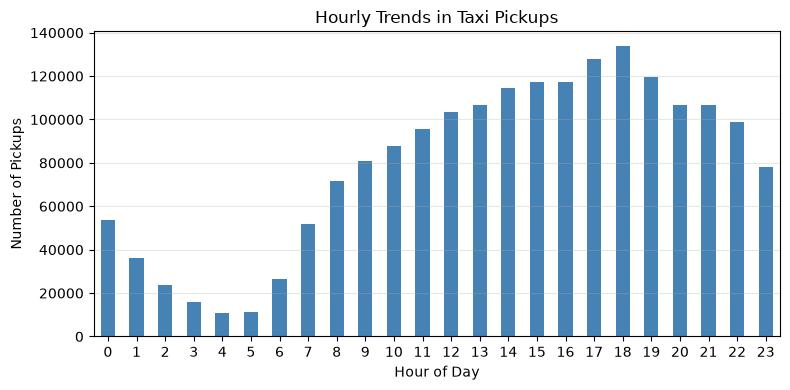

In [104]:
# Extract hour from pickup datetime and count pickups by hour
hourly_pickups = trip_df.groupby(trip_df['tpep_pickup_datetime'].dt.hour).size()

print("Hourly trends in taxi pickups:")
print(hourly_pickups)

# Visualize hourly trends
plt.figure(figsize=(8, 4))
hourly_pickups.plot(kind='bar', color='steelblue')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Pickups')
plt.title('Hourly Trends in Taxi Pickups')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



Daily trends in taxi pickups:
tpep_pickup_datetime
Monday       236297
Tuesday      274264
Wednesday    290489
Thursday     297282
Friday       282166
Saturday     276132
Sunday       239603
Name: count, dtype: int64


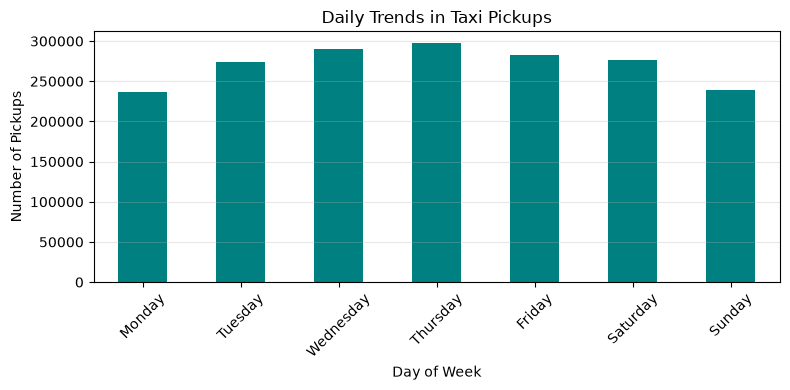

In [105]:
# Find and show the daily trends in taxi pickups (days of the week)
daily_pickups = trip_df['tpep_pickup_datetime'].dt.day_name().value_counts().reindex(
    ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
)

print("Daily trends in taxi pickups:")
print(daily_pickups)

plt.figure(figsize=(8,4))
daily_pickups.plot(kind='bar', color='teal')
plt.xlabel('Day of Week')
plt.ylabel('Number of Pickups')
plt.title('Daily Trends in Taxi Pickups')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



tpep_pickup_datetime
2023-01    152073
2023-02    144445
2023-03    168687
2023-04    162897
2023-05    174053
2023-06    163764
2023-07    143769
2023-08    139630
2023-09    140866
2023-10    174237
2023-11    165123
2023-12    166689
Freq: M, Name: count, dtype: int64


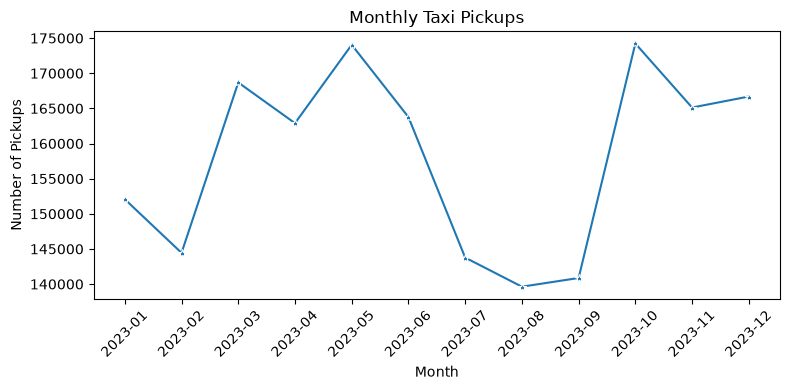

In [106]:
# Show the monthly trends in pickups
#df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
monthly = trip_df['tpep_pickup_datetime'].dt.to_period('M').value_counts().sort_index()
print(monthly)
plt.figure(figsize=(8,4))
sns.lineplot(x=monthly.index.astype(str), y=monthly.values, marker='*')
plt.xlabel('Month')
plt.ylabel('Number of Pickups')
plt.title('Monthly Taxi Pickups')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Financial Analysis

Take a look at the financial parameters like `fare_amount`, `tip_amount`, `total_amount`, and also `trip_distance`. Do these contain zero/negative values?

In [107]:
# Analyse the above parameters
# Check zero and negative values for selected columns
cols_to_check = ['fare_amount', 'tip_amount', 'total_amount', 'trip_distance']

for col in cols_to_check:
    zeros = (trip_df[col] == 0).sum()
    negatives = (trip_df[col] < 0).sum()
    print(f"{col}: zeros={zeros}, negatives={negatives}")


fare_amount: zeros=588, negatives=0
tip_amount: zeros=435847, negatives=0
total_amount: zeros=264, negatives=0
trip_distance: zeros=37625, negatives=0


Do you think it is beneficial to create a copy DataFrame leaving out the zero values from these?

**3.1.3** <font color = red>[2 marks]</font> <br>
Filter out the zero values from the above columns.

**Note:** The distance might be 0 in cases where pickup and drop is in the same zone. Do you think it is suitable to drop such cases of zero distance?

In [108]:
# Create a df with non zero entries for the selected parameters.
filtered_zero = trip_df[~((trip_df['total_amount'] == 0) | (trip_df['fare_amount'] == 0))]
print(filtered_zero.shape)

(1895645, 19)


**3.1.4** <font color = red>[3 marks]</font> <br>
Analyse the monthly revenue (`total_amount`) trend

tpep_pickup_datetime
2023-01    4159891.27
2023-02    3941722.56
2023-03    4754930.43
2023-04    4677024.40
2023-05    5109398.92
2023-06    4809116.05
2023-07    4176625.37
2023-08    4080281.12
2023-09    4382995.30
2023-10    5179162.33
2023-11    4807650.63
2023-12    4861646.54
Freq: M, Name: total_amount, dtype: float64


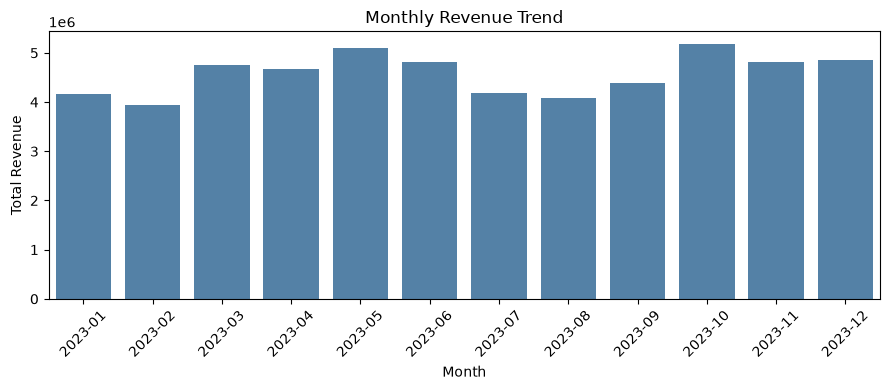

In [109]:
# Group data by month and analyse monthly revenue

monthly_revenue = (
    trip_df
    .groupby(trip_df['tpep_pickup_datetime'].dt.to_period('M'))['total_amount']
    .sum()
    .sort_index()
)

print(monthly_revenue)

plt.figure(figsize=(9, 4))
sns.barplot(
    x=monthly_revenue.index.astype(str),
    y=monthly_revenue.values,
    color='steelblue'
)
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.title('Monthly Revenue Trend')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**3.1.5** <font color = red>[3 marks]</font> <br>
Show the proportion of each quarter of the year in the revenue

tpep_pickup_datetime
2023Q1    0.234009
2023Q2    0.265661
2023Q3    0.230066
2023Q4    0.270265
Freq: Q-DEC, Name: total_amount, dtype: float64


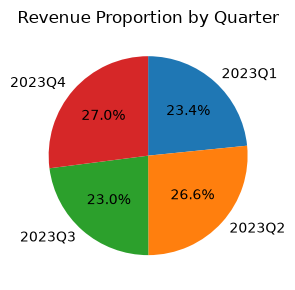

In [110]:
# Calculate proportion of each quarter
quarterly_revenue = (
    trip_df
    .groupby(trip_df['tpep_pickup_datetime'].dt.to_period('Q'))['total_amount']
    .sum()
    .sort_index()
)

quarterly_proportion = quarterly_revenue / quarterly_revenue.sum()

print(quarterly_proportion)

plt.figure(figsize=(6, 3))
quarterly_proportion.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,
    ylabel=''
)
plt.title('Revenue Proportion by Quarter')
plt.tight_layout()
plt.show()


**3.1.6** <font color = red>[3 marks]</font> <br>
Visualise the relationship between `trip_distance` and `fare_amount`. Also find the correlation value for these two.

**Hint:** You can leave out the trips with trip_distance = 0

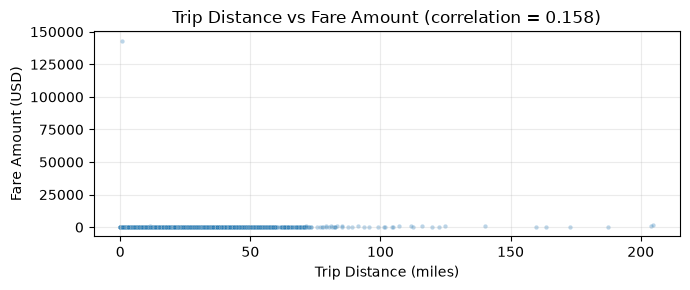

Correlation between trip_distance and fare_amount: 0.1576265828190202


In [111]:
# Show how trip fare is affected by distance
subset = trip_df[trip_df['trip_distance'] > 0].copy()

corr_value = subset['trip_distance'].corr(subset['fare_amount'])

plt.figure(figsize=(7, 3))
sns.scatterplot(
    data=subset,
    x='trip_distance',
    y='fare_amount',
    alpha=0.3,
    s=10
)
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Fare Amount (USD)')
plt.title(f'Trip Distance vs Fare Amount (correlation = {corr_value:.3f})')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Correlation between trip_distance and fare_amount:", corr_value)


**3.1.7** <font color = red>[5 marks]</font> <br>
Find and visualise the correlation between:
1. `fare_amount` and trip duration (pickup time to dropoff time)
2. `fare_amount` and `passenger_count`
3. `tip_amount` and `trip_distance`

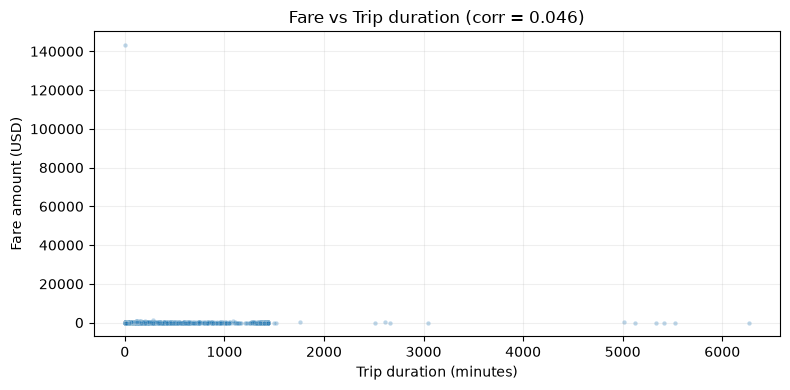

Correlation (fare_amount, trip_duration): 0.0458032006632278


In [112]:
# Show relationship between fare and trip duration
subset = trip_df[trip_df['trip_duration'] > 0].copy()
corr = subset['fare_amount'].corr(subset['trip_duration'])

plt.figure(figsize=(8,4))
sns.scatterplot(data=subset, x='trip_duration', y='fare_amount', alpha=0.3, s=10)
plt.xlabel('Trip duration (minutes)')
plt.ylabel('Fare amount (USD)')
plt.title(f'Fare vs Trip duration (corr = {corr:.3f})')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Correlation (fare_amount, trip_duration):", corr)



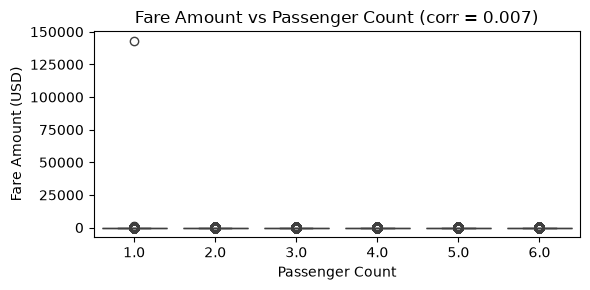

Correlation between fare_amount and passenger_count: 0.006652110317802516


In [113]:
# Show relationship between fare and number of passengers

subset = trip_df[trip_df['passenger_count'] > 0].copy()
corr = subset['fare_amount'].corr(subset['passenger_count'])

plt.figure(figsize=(6, 3))
sns.boxplot(x='passenger_count', y='fare_amount', data=subset)
plt.xlabel('Passenger Count')
plt.ylabel('Fare Amount (USD)')
plt.title(f'Fare Amount vs Passenger Count (corr = {corr:.3f})')
plt.tight_layout()
plt.show()

print("Correlation between fare_amount and passenger_count:", corr)

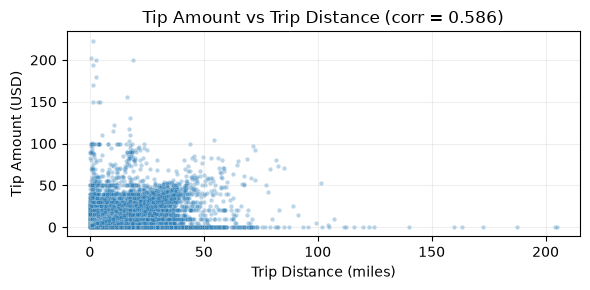

Correlation between tip_amount and trip_distance: 0.5855506543141916


In [114]:
# Show relationship between tip and trip distance
subset = trip_df[trip_df['trip_distance'] > 0].copy()
corr = subset['tip_amount'].corr(subset['trip_distance'])

plt.figure(figsize=(6,3))
sns.scatterplot(data=subset, x='trip_distance', y='tip_amount', alpha=0.3, s=10)
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Tip Amount (USD)')
plt.title(f'Tip Amount vs Trip Distance (corr = {corr:.3f})')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Correlation between tip_amount and trip_distance:", corr)




**3.1.8** <font color = red>[3 marks]</font> <br>
Analyse the distribution of different payment types (`payment_type`)

Payment type counts:
payment_type
0      64844
1    1492299
2     316412
3       9006
4      13672
Name: count, dtype: int64

Payment type proportions:
payment_type
0    0.034196
1    0.786981
2    0.166863
3    0.004749
4    0.007210
Name: count, dtype: float64


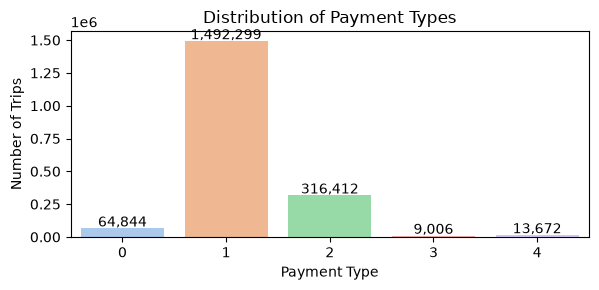

In [115]:
# Analyse the distribution of different payment types (payment_type).
payment_counts = trip_df['payment_type'].value_counts().sort_index()
payment_props = payment_counts / payment_counts.sum()

print("Payment type counts:")
print(payment_counts)
print("\nPayment type proportions:")
print(payment_props)

plt.figure(figsize=(6,3))
sns.barplot(x=payment_counts.index.astype(int), y=payment_counts.values, palette='pastel')
plt.xlabel('Payment Type')
plt.ylabel('Number of Trips')
plt.title('Distribution of Payment Types')

plt.xticks(rotation=0)
for i, value in enumerate(payment_counts.values):
    plt.text(i, value + payment_counts.max() * 0.01, f"{value:,}", ha='center')
plt.tight_layout()
plt.show()

- 1= Credit card
- 2= Cash
- 3= No charge
- 4= Dispute



##### Geographical Analysis

For this, you have to use the *taxi_zones.shp* file from the *taxi_zones* folder.

There would be multiple files inside the folder (such as *.shx, .sbx, .sbn* etc). You do not need to import/read any of the files other than the shapefile, *taxi_zones.shp*.

Do not change any folder structure - all the files need to be present inside the folder for it to work.

The folder structure should look like this:
```
Taxi Zones
|- taxi_zones.shp.xml
|- taxi_zones.prj
|- taxi_zones.sbn
|- taxi_zones.shp
|- taxi_zones.dbf
|- taxi_zones.shx
|- taxi_zones.sbx

 ```

 You only need to read the `taxi_zones.shp` file. The *shp* file will utilise the other files by itself.

We will use the *GeoPandas* library for geopgraphical analysis
```
import geopandas as gpd
```

More about geopandas and shapefiles: [About](https://geopandas.org/en/stable/about.html)


Reading the shapefile is very similar to *Pandas*. Use `gpd.read_file()` function to load the data (*taxi_zones.shp*) as a GeoDataFrame. Documentation: [Reading and Writing Files](https://geopandas.org/en/stable/docs/user_guide/io.html)

In [116]:
pip install geopandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


**3.1.9** <font color = red>[2 marks]</font> <br>
Load the shapefile and display it.

In [117]:
import geopandas as gpd

# Read the shapefile using geopandas
zones = gpd.read_file('../../Datasets and Dictionary/taxi_zones/taxi_zones.shp')
zones.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


Now, if you look at the DataFrame created, you will see columns like: `OBJECTID`,`Shape_Leng`, `Shape_Area`, `zone`, `LocationID`, `borough`, `geometry`.
<br><br>

Now, the `locationID` here is also what we are using to mark pickup and drop zones in the trip records.

The geometric parameters like shape length, shape area and geometry are used to plot the zones on a map.

This can be easily done using the `plot()` method.

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    263 non-null    int32   
 1   Shape_Leng  263 non-null    float64 
 2   Shape_Area  263 non-null    float64 
 3   zone        263 non-null    str     
 4   LocationID  263 non-null    int32   
 5   borough     263 non-null    str     
 6   geometry    263 non-null    geometry
dtypes: float64(2), geometry(1), int32(2), str(2)
memory usage: 18.5 KB
None


<Axes: >

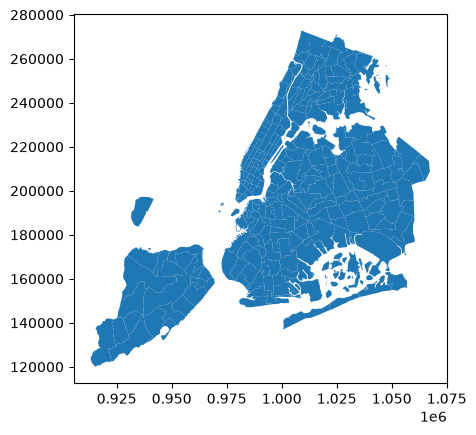

In [118]:
print(zones.info())
zones.plot()

Now, you have to merge the trip records and zones data using the location IDs.



**3.1.10** <font color = red>[3 marks]</font> <br>
Merge the zones data into trip data using the `locationID` and `PULocationID` columns.

In [119]:
#Merge zones and trip records using locationID and PULocationID

pickup_zones = zones[['LocationID', 'zone', 'borough']].rename(
    columns={
        'LocationID': 'PULocationID',
        'zone': 'PUZone',
        'borough': 'PUBorough'
    }
)

trip_df = trip_df.merge(pickup_zones, on='PULocationID', how='left')

trip_df[['PULocationID', 'PUZone', 'PUBorough']].head()



,PULocationID,PUZone,PUBorough
0,138,LaGuardia Airport,Queens
1,161,Midtown Center,Manhattan
2,237,Upper East Side South,Manhattan
3,143,Lincoln Square West,Manhattan
4,66,DUMBO/Vinegar Hill,Brooklyn


**3.1.11** <font color = red>[3 marks]</font> <br>
Group data by location IDs to find the total number of trips per location ID

In [120]:
# Group data by pickup location and calculate the number of trips
trips_per_location = (
    trip_df
    .groupby(['PULocationID','PUZone'])
    .size()
    .rename('trip_count')
    .sort_values(ascending=False)
)

trips_per_location.head()


PULocationID  PUZone               
132           JFK Airport              97035
237           Upper East Side South    88607
161           Midtown Center           87586
236           Upper East Side North    79755
162           Midtown East             66712
Name: trip_count, dtype: int64

**3.1.12** <font color = red>[2 marks]</font> <br>
Now, use the grouped data to add number of trips to the GeoDataFrame.

We will use this to plot a map of zones showing total trips per zone.

In [121]:
# Merge trip counts back to the zones GeoDataFrame
zones = zones.merge(trips_per_location, left_on=['LocationID', 'zone'], right_index=True, how='left')
zones['trip_count'] = zones['trip_count'].fillna(0)

zones[['LocationID', 'zone', 'borough', 'trip_count']].head(10)
zones['trip_count'] = zones['trip_count'].fillna(0)

# Display the updated GeoDataFrame
zones[['LocationID', 'zone', 'borough', 'trip_count']].head(10)




,LocationID,zone,borough,trip_count
0,1,Newark Airport,EWR,218.0
1,2,Jamaica Bay,Queens,2.0
2,3,Allerton/Pelham Gardens,Bronx,44.0
3,4,Alphabet City,Manhattan,2355.0
4,5,Arden Heights,Staten Island,13.0
5,6,Arrochar/Fort Wadsworth,Staten Island,25.0
6,7,Astoria,Queens,1037.0
7,8,Astoria Park,Queens,6.0
8,9,Auburndale,Queens,26.0
9,10,Baisley Park,Queens,590.0


The next step is creating a color map (choropleth map) showing zones by the number of trips taken.

Again, you can use the `zones.plot()` method for this. [Plot Method GPD](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html#geopandas.GeoDataFrame.plot)

But first, you need to define the figure and axis for the plot.

`fig, ax = plt.subplots(1, 1, figsize = (12, 10))`

This function creates a figure (fig) and a single subplot (ax)

---

After setting up the figure and axis, we can proceed to plot the GeoDataFrame on this axis. This is done in the next step where we use the plot method of the GeoDataFrame.

You can define the following parameters in the `zones.plot()` method:
```
column = '',
ax = ax,
legend = True,
legend_kwds = {'label': "label", 'orientation': "<horizontal/vertical>"}
```

To display the plot, use `plt.show()`.

**3.1.13** <font color = red>[3 marks]</font> <br>
Plot a color-coded map showing zone-wise trips

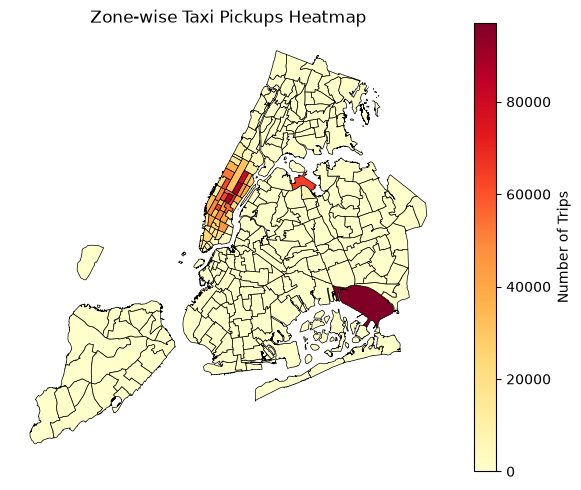

In [122]:
# Define figure and axis
fig, ax = plt.subplots(1, 1, figsize = (6, 5))

zones.plot(
    column='trip_count',
    ax=ax,
    legend=True,
    legend_kwds={'label': "Number of Trips", 'orientation': "vertical"},
    cmap='YlOrRd',
    edgecolor='k',
    linewidth=0.5
)
plt.title('Zone-wise Taxi Pickups Heatmap')
plt.axis('off')
plt.tight_layout()
plt.show()



In [123]:
# can you try displaying the zones DF sorted by the number of trips?

zones_sorted = zones.sort_values('trip_count', ascending=False)
print(zones_sorted[['LocationID', 'zone', 'borough', 'trip_count']].head(20))

     LocationID                          zone    borough  trip_count
131         132                   JFK Airport     Queens     97035.0
236         237         Upper East Side South  Manhattan     88607.0
160         161                Midtown Center  Manhattan     87586.0
235         236         Upper East Side North  Manhattan     79755.0
161         162                  Midtown East  Manhattan     66712.0
137         138             LaGuardia Airport     Queens     64441.0
185         186  Penn Station/Madison Sq West  Manhattan     64314.0
229         230     Times Sq/Theatre District  Manhattan     62669.0
141         142           Lincoln Square East  Manhattan     62662.0
169         170                   Murray Hill  Manhattan     55931.0
162         163                 Midtown North  Manhattan     54838.0
238         239         Upper West Side South  Manhattan     52692.0
233         234                      Union Sq  Manhattan     50785.0
47           48                  C

Here we have completed the temporal, financial and geographical analysis on the trip records.

**Compile your findings from general analysis below:**

You can consider the following points:

* Busiest hours, days and months
* Trends in revenue collected
* Trends in quarterly revenue
* How fare depends on trip distance, trip duration and passenger counts
* How tip amount depends on trip distance
* Busiest zones


Based on above analysis here are the findings:
- Busiest hours – 11 am to evening 10pm. Highest at 6 pm. 
  Low pickups:  midnight 1 am to 5 am.
  From 6 pm to 6 am in morning pickup count decreases. From 6 am to 6 pm pickup count increases.
  Number of pickups slightly low on Monday and Sunday. Highest on Thursday.
  Pick periods where the pickups are high – March to June and Oct to Dec.
  Low periods where pickups are less - Jan, Feb,July to September.
- Revenue is comparatively less in Jan, Feb, July, Aug, Sep than other months. But the difference is not that significant compared to difference in number of pickups for   respective months.
- Revenue proportion is slightly high in Q2 and Q4 quarters. Q1 and Q3 quarters also perform well.
- Fare amount doesn't grow much w.r.t. trip distance or trip duration or passanger count. Though fare amount increases slightly with increare in trip distance or trip duration or passanger count
- Tip amount is higher when trip distance increases, both have positive co-relation.
- Busiest zones are - JFK Airport , Upper East Side South, Midtown Center, Midtown East, LaGuardia Airport, Penn Station/Madison Sq West, Times Sq/Theatre District, Lincoln Square East, Murray Hill, Midtown North




#### **3.2** Detailed EDA: Insights and Strategies
<font color = red>[50 marks]</font> <br>

Having performed basic analyses for finding trends and patterns, we will now move on to some detailed analysis focussed on operational efficiency, pricing strategies, and customer experience.

##### Operational Efficiency

Analyze variations by time of day and location to identify bottlenecks or inefficiencies in routes

**3.2.1** <font color = red>[3 marks]</font> <br>
Identify slow routes by calculating the average time taken by cabs to get from one zone to another at different hours of the day.

Speed on a route *X* for hour *Y* = (*distance of the route X / average trip duration for hour Y*)

In [124]:
# Find slowest routes (PULocationID -> DOLocationID) by hour
df = trip_df[(trip_df['trip_duration'] > 0) & (trip_df['trip_distance'] > 0)].copy()
df['hour'] = df['tpep_pickup_datetime'].dt.hour

grp = (
    df
    .groupby(['hour','PULocationID','DOLocationID'])
    .agg(avg_distance=('trip_distance','mean'),
         avg_duration=('trip_duration','mean'),
         trip_count=('trip_distance','count'))
    .reset_index()
)

# average speed in mph
grp['avg_speed'] = grp['avg_distance'] / grp['avg_duration'] * 60

# require minimum trips to avoid noise
MIN_TRIPS = 30
grp_filtered = grp[grp['trip_count'] >= MIN_TRIPS]

# get top N slowest routes per hour
N = 1
slowest_per_hour = grp_filtered.sort_values(['hour','avg_speed']).groupby('hour').head(N)

# attach zone names for readability
drop_zones = zones[['LocationID','zone']].rename(columns={'LocationID':'DOLocationID','zone':'DOZone'})
slowest_per_hour = (
    slowest_per_hour
    .merge(pickup_zones, on='PULocationID', how='left')
    .merge(drop_zones, on='DOLocationID', how='left')
    [['hour','PULocationID','PUZone','DOLocationID','DOZone','trip_count','avg_distance','avg_duration','avg_speed']]
    .sort_values(['hour','avg_speed'])
)

slowest_per_hour

,hour,PULocationID,PUZone,DOLocationID,DOZone,trip_count,avg_distance,avg_duration,avg_speed
0,0,234,Union Sq,113,Greenwich Village North,33,0.867879,47.832323,1.088651
1,1,148,Lower East Side,148,Lower East Side,66,0.609848,27.368687,1.336963
2,2,79,East Village,158,Meatpacking/West Village West,30,1.686667,103.230556,0.980330
3,3,148,Lower East Side,148,Lower East Side,47,0.702128,34.586879,1.218024
4,4,148,Lower East Side,79,East Village,32,0.735938,4.457292,9.906520
5,5,48,Clinton East,230,Times Sq/Theatre District,43,0.801163,4.714729,10.195659
6,6,100,Garment District,170,Murray Hill,47,0.977021,7.752482,7.561614
7,7,43,Central Park,43,Central Park,36,1.220833,45.056481,1.625737
8,8,75,East Harlem South,238,Upper West Side North,36,1.303889,47.710648,1.639746
9,9,170,Murray Hill,164,Midtown South,80,0.697625,25.140417,1.664949


How does identifying high-traffic, high-demand routes help us?

High traffic, high demand routes -
1. Vehicles with higher capacity to be deployed to the route
2. Availaibility to be kept high on these routes on pick hours - give faster service to customers
3. Drivers are well aware of traffic in advance on pick hours - less fuel consumption cars prefered on these routes

**3.2.2** <font color = red>[3 marks]</font> <br>
Calculate the number of trips at each hour of the day and visualise them. Find the busiest hour and show the number of trips for that hour.

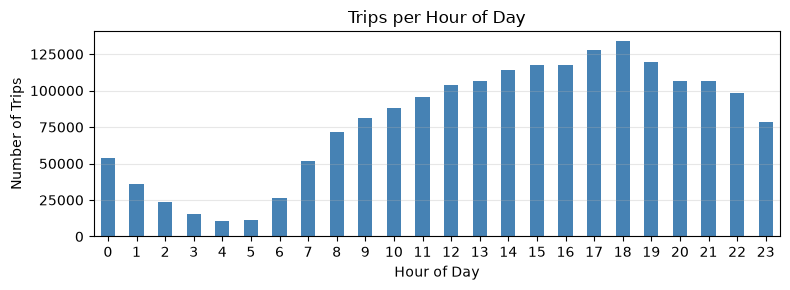

Busiest hour: 18:00
Number of trips during busiest hour: 133,931


In [125]:
# Visualise the number of trips per hour and find the busiest hour
plt.figure(figsize=(8, 3))

hourly_pickups.plot(kind='bar', color='steelblue')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips')
plt.title('Trips per Hour of Day')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

busiest_hour = hourly_pickups.idxmax()
busiest_count = hourly_pickups.max()

print(f"Busiest hour: {busiest_hour}:00")
print(f"Number of trips during busiest hour: {busiest_count:,}")


Remember, we took a fraction of trips. To find the actual number, you have to scale the number up by the sampling ratio.

**3.2.3** <font color = red>[2 mark]</font> <br>
Find the actual number of trips in the five busiest hours

In [126]:
# Scale up the number of trips
# Fill in the value of your sampling fraction and use that to scale up the numbers

sampling_fraction = 0.05  
scaling_factor = 1 / sampling_fraction

hourly_actual_trips = hourly_pickups * scaling_factor

print(f"Sampling fraction: {sampling_fraction}")
print(f"Scaling factor: {scaling_factor:.0f}")
print("\nFive busiest hours (estimated actual trips):")
print(hourly_actual_trips.sort_values(ascending=False).head(5).astype(int))

Sampling fraction: 0.05
Scaling factor: 20

Five busiest hours (estimated actual trips):
tpep_pickup_datetime
18    2678620
17    2557160
19    2392980
16    2349940
15    2347920
dtype: int64


**3.2.4** <font color = red>[3 marks]</font> <br>
Compare hourly traffic pattern on weekdays. Also compare for weekend.

<Figure size 1000x400 with 0 Axes>

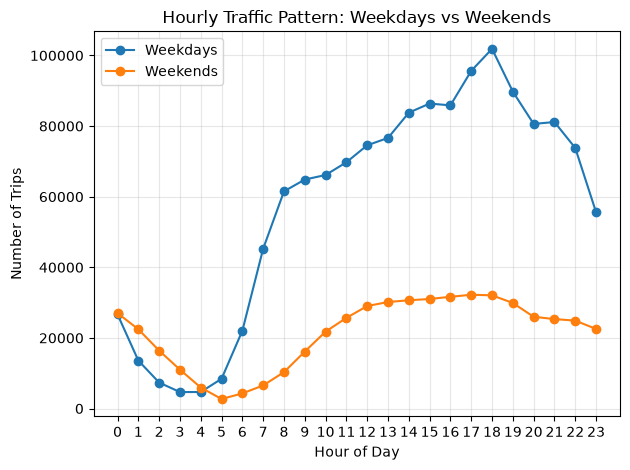


Busiest weekday hour: 18 (101,873 trips)
Busiest weekend hour: 17:00 (32,226 trips)


In [127]:
# Compare traffic trends for the week days and weekends

# Compare hourly traffic on weekdays vs weekends
day_of_week = trip_df['tpep_pickup_datetime'].dt.dayofweek

weekday_counts = (
    trip_df.loc[day_of_week < 5, 'tpep_pickup_datetime']
    .dt.hour
    .value_counts()
    .sort_index()
    .reindex(range(24), fill_value=0)
)

weekend_counts = (
    trip_df.loc[day_of_week >= 5, 'tpep_pickup_datetime']
    .dt.hour
    .value_counts()
    .sort_index()
    .reindex(range(24), fill_value=0)
)

traffic_compare = pd.DataFrame({
    'Weekdays': weekday_counts,
    'Weekends': weekend_counts
})

plt.figure(figsize=(10, 4))
traffic_compare.plot(kind='line', marker='o')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips')
plt.title('Hourly Traffic Pattern: Weekdays vs Weekends')
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nBusiest weekday hour: {weekday_counts.idxmax()} ({weekday_counts.max():,} trips)")
print(f"Busiest weekend hour: {weekend_counts.idxmax()}:00 ({weekend_counts.max():,} trips)")

What can you infer from the above patterns? How will finding busy and quiet hours for each day help us?
- Drivers can plan taking quality rest during quiet hours
- Drivers can plan car maintainance activities / fuel recharge during quite hours
- Deploying more pasanger vehicles during busy hours - may help reducing traffic
- Fare charges might vary based on the availaibily of vehicles at rush hours / quite hours


**3.2.5** <font color = red>[3 marks]</font> <br>
Identify top 10 zones with high hourly pickups. Do the same for hourly dropoffs. Show pickup and dropoff trends in these zones.

In [128]:
# Identify top 10 zones with high hourly pickups and dropoffs
# Calculate hourly pickups by zone
hourly_pickups_by_zone = (trip_df.groupby([trip_df['tpep_pickup_datetime'].dt.hour, 'PULocationID', 'PUZone']).size().reset_index(name='pickup_count'))

# Find top 10 zones by total hourly pickups
top_10_pickup_zones = (hourly_pickups_by_zone.groupby('PULocationID')['pickup_count'].sum().nlargest(10).index.tolist())

# Filter data for top 10 pickup zones
top_pickup_data = hourly_pickups_by_zone[hourly_pickups_by_zone['PULocationID'].isin(top_10_pickup_zones)].copy()

# Calculate hourly dropoffs by zone
hourly_dropoffs_by_zone = (trip_df.groupby([trip_df['tpep_dropoff_datetime'].dt.hour, 'DOLocationID']).size().reset_index(name='dropoff_count'))

# Map dropoff LocationID to zone name (kept as PUZone to remain consistent with later usage)
drop_zone_map = zones[['LocationID', 'zone']].rename(columns={'LocationID': 'DOLocationID', 'zone': 'PUZone'})
hourly_dropoffs_by_zone = hourly_dropoffs_by_zone.merge(drop_zone_map, on='DOLocationID', how='left')

top_10_dropoff_zones = (hourly_dropoffs_by_zone.groupby('DOLocationID')['dropoff_count'].sum().nlargest(10).index.tolist())

top_dropoff_data = hourly_dropoffs_by_zone[hourly_dropoffs_by_zone['DOLocationID'].isin(top_10_dropoff_zones)].copy()

print("Top 10 Pickup Zones:")
print(top_pickup_data.groupby(['PULocationID', 'PUZone'])['pickup_count'].sum().nlargest(10))

print("\nTop 10 Dropoff Zones:")
print(top_dropoff_data.groupby(['DOLocationID','PUZone'])['dropoff_count'].sum().nlargest(10))

Top 10 Pickup Zones:
PULocationID  PUZone                      
132           JFK Airport                     97035
237           Upper East Side South           88607
161           Midtown Center                  87586
236           Upper East Side North           79755
162           Midtown East                    66712
138           LaGuardia Airport               64441
186           Penn Station/Madison Sq West    64314
230           Times Sq/Theatre District       62669
142           Lincoln Square East             62662
170           Murray Hill                     55931
Name: pickup_count, dtype: int64

Top 10 Dropoff Zones:
DOLocationID  PUZone                   
236           Upper East Side North        83442
237           Upper East Side South        79425
161           Midtown Center               73728
230           Times Sq/Theatre District    57969
170           Murray Hill                  55799
162           Midtown East                 53703
142           Lincoln Squa

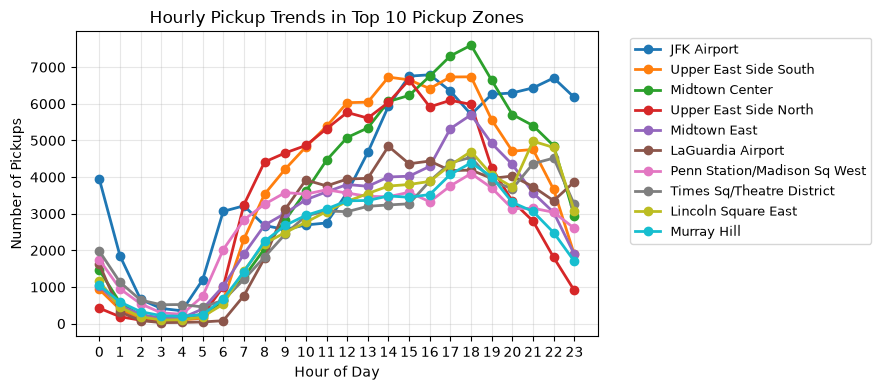

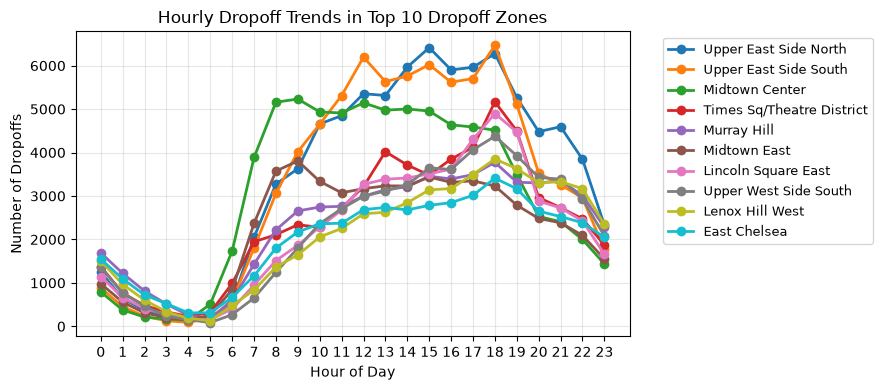

In [129]:
# Top 10 pickup zones by total trips (hourly trends) and top 10 dropoff zones (hourly trends)
# Visualize pickup trends for top 10 zones
plt.figure(figsize=(9, 4))
for zone_id in top_10_pickup_zones:
    zone_data = top_pickup_data[top_pickup_data['PULocationID'] == zone_id]
    zone_name = zone_data['PUZone'].iloc[0]
    plt.plot(
        zone_data['tpep_pickup_datetime'],
        zone_data['pickup_count'],
        marker='o',
        label=zone_name,
        linewidth=2
    )

plt.xlabel('Hour of Day')
plt.ylabel('Number of Pickups')
plt.title('Hourly Pickup Trends in Top 10 Pickup Zones')
plt.xticks(range(24))
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Visualize dropoff trends for top 10 zones
plt.figure(figsize=(9, 4))
for zone_id in top_10_dropoff_zones:
    zone_data = top_dropoff_data[top_dropoff_data['DOLocationID'] == zone_id]
    zone_name = zone_data['PUZone'].iloc[0]
    plt.plot(
        zone_data['tpep_dropoff_datetime'],
        zone_data['dropoff_count'],
        marker='o',
        label=zone_name,
        linewidth=2
    )

plt.xlabel('Hour of Day')
plt.ylabel('Number of Dropoffs')
plt.title('Hourly Dropoff Trends in Top 10 Dropoff Zones')
plt.xticks(range(24))
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**3.2.6** <font color = red>[3 marks]</font> <br>
Find the ratio of pickups and dropoffs in each zone. Display the 10 highest (pickup/drop) and 10 lowest (pickup/drop) ratios.

In [130]:
# Find the top 10 and bottom 10 pickup/dropoff ratios
pickup_counts = trip_df.groupby('PULocationID').size().rename('pickup_count').reset_index()
dropoff_counts = trip_df.groupby('DOLocationID').size().rename('dropoff_count').reset_index()

zone_labels = zones[['LocationID', 'zone']].rename(
    columns={'LocationID': 'location_id', 'zone': 'zone_name'}
)

zone_counts = (
    pickup_counts.rename(columns={'PULocationID': 'location_id'})
    .merge(dropoff_counts.rename(columns={'DOLocationID': 'location_id'}), on='location_id', how='outer')
    .merge(zone_labels, on='location_id', how='left')
)

zone_counts[['pickup_count', 'dropoff_count']] = zone_counts[['pickup_count', 'dropoff_count']].fillna(0).astype(int)
zone_counts['pickup_drop_ratio'] = zone_counts['pickup_count'] / zone_counts['dropoff_count'].replace({0: pd.NA})

top10 = zone_counts.sort_values('pickup_drop_ratio', ascending=False).head(10)
bottom10 = zone_counts.sort_values('pickup_drop_ratio', ascending=True).head(10)

print("Top 10 zones by pickup/dropoff ratio:")
print(top10[['location_id', 'zone_name','pickup_drop_ratio']])

print("\nBottom 10 zones by pickup/dropoff ratio:")
print(bottom10[['location_id', 'zone_name', 'pickup_drop_ratio']])


Top 10 zones by pickup/dropoff ratio:
     location_id                     zone_name pickup_drop_ratio
70            70                 East Elmhurst          8.147287
128          132                   JFK Airport           4.26415
134          138             LaGuardia Airport          2.620618
182          186  Penn Station/Madison Sq West            1.5569
110          114       Greenwich Village South          1.376644
42            43                  Central Park          1.368644
245          249                  West Village          1.332328
158          162                  Midtown East           1.24224
157          161                Midtown Center          1.187961
100          100              Garment District          1.186956

Bottom 10 zones by pickup/dropoff ratio:
     location_id                            zone_name pickup_drop_ratio
172          176                              Oakwood               0.0
99            99                      Freshkills Park        

**3.2.7** <font color = red>[3 marks]</font> <br>
Identify zones with high pickup and dropoff traffic during night hours (11PM to 5AM)

In [131]:
# During night hours (11pm to 5am) find the top 10 pickup and dropoff zones
# Note that the top zones should be of night hours and not the overall top zones
night_hours = [23,0,1,2,3,4,5]

# Top 10 pickup zones during night hours
pick_n = trip_df[trip_df['tpep_pickup_datetime'].dt.hour.isin(night_hours)]
top10_pick = (
    pick_n.groupby(['PULocationID','PUZone'])
    .size()
    .reset_index(name='pickup_count')
    .sort_values('pickup_count', ascending=False)
    .head(10)
)
print("Top 10 pickup zones (11PM to 5AM):")
print(top10_pick)

# Top 10 dropoff zones during night hours
drop_n = trip_df[trip_df['tpep_dropoff_datetime'].dt.hour.isin(night_hours)]
drop_zone_map = zones[['LocationID','zone']].rename(columns={'LocationID':'DOLocationID','zone':'DOZone'})
top10_drop = (
    drop_n.groupby('DOLocationID')
    .size()
    .reset_index(name='dropoff_count')
    .merge(drop_zone_map, on='DOLocationID', how='left')
    .sort_values('dropoff_count', ascending=False)
    .head(10)
)
print("\nTop 10 dropoff zones (11PM to 5AM):")
print(top10_drop)


Top 10 pickup zones (11PM to 5AM):
     PULocationID                        PUZone  pickup_count
71             79                  East Village         16466
116           132                   JFK Airport         14584
225           249                  West Village         13144
42             48                  Clinton East         10834
132           148               Lower East Side         10191
100           114       Greenwich Village South          9193
207           230     Times Sq/Theatre District          8500
166           186  Penn Station/Madison Sq West          7135
147           164                 Midtown South          6468
60             68                  East Chelsea          6401

Top 10 dropoff zones (11PM to 5AM):
     DOLocationID  dropoff_count                     DOZone
78             79           9316               East Village
46             48           7809               Clinton East
165           170           6947                Murray Hill
67    

Now, let us find the revenue share for the night time hours and the day time hours. After this, we will move to deciding a pricing strategy.

**3.2.8** <font color = red>[2 marks]</font> <br>
Find the revenue share for nighttime and daytime hours.

Night revenue (11PM-5AM): $6,756,708.89
Day revenue: $48,190,030.50
Night share: 12.30%
Day share: 87.70%


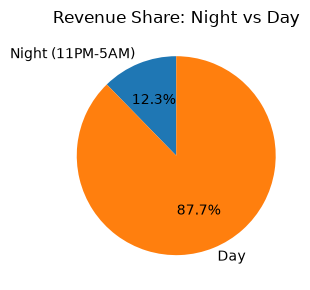

In [132]:
# Filter for night hours (11 PM to 5 AM)
night_mask = trip_df['tpep_pickup_datetime'].dt.hour.isin(night_hours)
night_revenue = trip_df.loc[night_mask, 'total_amount'].sum()
total_revenue = trip_df['total_amount'].sum()
day_revenue = total_revenue - night_revenue

print(f"Night revenue (11PM-5AM): ${night_revenue:,.2f}")
print(f"Day revenue: ${day_revenue:,.2f}")
print(f"Night share: {night_revenue/total_revenue:.2%}")
print(f"Day share: {day_revenue/total_revenue:.2%}")

plt.figure(figsize=(5,3))
pd.Series([night_revenue, day_revenue], index=['Night (11PM-5AM)','Day']).plot(
    kind='pie', autopct='%1.1f%%', startangle=90, ylabel=''
)
plt.title('Revenue Share: Night vs Day')
plt.tight_layout()
plt.show()


##### Pricing Strategy

**3.2.9** <font color = red>[2 marks]</font> <br>
For the different passenger counts, find the average fare per mile per passenger.

For instance, suppose the average fare per mile for trips with 3 passengers is 3 USD/mile, then the fare per mile per passenger will be 1 USD/mile.

Average Fare per Mile per Passenger by Passenger Count:
                 avg_fare_per_mile_per_passenger
passenger_count                                 
1.0                                    11.003255
2.0                                     6.434912
3.0                                     3.907743
4.0                                     4.360870
5.0                                     1.709582
6.0                                     1.350662


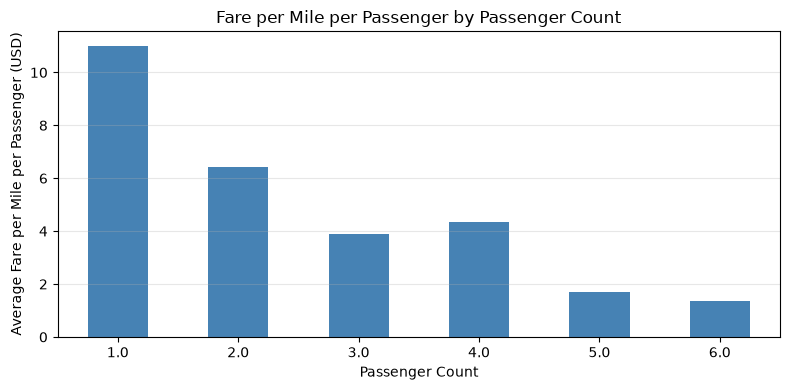

In [133]:
# Analyse the fare per mile per passenger for different passenger counts

# Filter trips with positive distance and passenger count
analysis_df = trip_df[(trip_df['trip_distance'] > 0) & (trip_df['passenger_count'] > 0)].copy()

# Calculate fare per mile per passenger for each trip
analysis_df['fare_per_mile_per_passenger'] = analysis_df['fare_amount'] / analysis_df['trip_distance'] / analysis_df['passenger_count']

# Group by passenger count and calculate average
fare_per_passenger = (analysis_df.groupby('passenger_count')
    .agg(
        avg_fare_per_mile_per_passenger=('fare_per_mile_per_passenger', 'mean')
    ).sort_index()
)

print("Average Fare per Mile per Passenger by Passenger Count:")
print(fare_per_passenger)

plt.figure(figsize=(8, 4))
fare_per_passenger['avg_fare_per_mile_per_passenger'].plot(kind='bar', color='steelblue')
plt.xlabel('Passenger Count')
plt.ylabel('Average Fare per Mile per Passenger (USD)')
plt.title('Fare per Mile per Passenger by Passenger Count')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**3.2.10** <font color = red>[3 marks]</font> <br>
Find the average fare per mile by hours of the day and by days of the week

Average Fare per Mile by Hour of Day:
hour
0     10.466255
1     11.202882
2      9.871727
3     10.799226
4     13.228243
5     13.890256
6     10.984566
7     10.162749
8     10.305552
9     10.463414
10    13.102917
11    10.937973
12    12.009172
13    11.937688
14    11.523513
15    12.495522
16    13.813875
17    11.964355
18    11.545668
19    11.550656
20     9.559832
21     9.484459
22    10.124651
23    10.709787
Name: fare_per_mile, dtype: float64


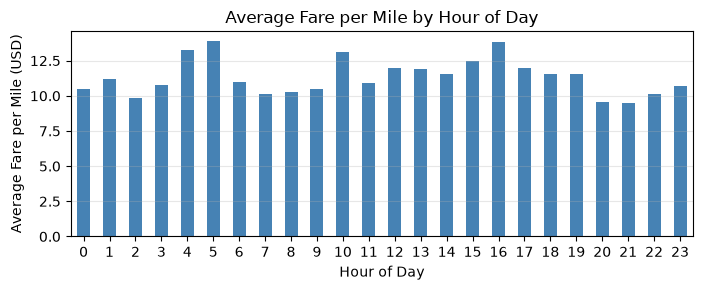


Average Fare per Mile by Day of Week:
day_of_week
Monday       10.925552
Tuesday      12.081706
Wednesday    11.039181
Thursday     11.239192
Friday       10.903320
Saturday     10.871707
Sunday       12.494536
Name: fare_per_mile, dtype: float64


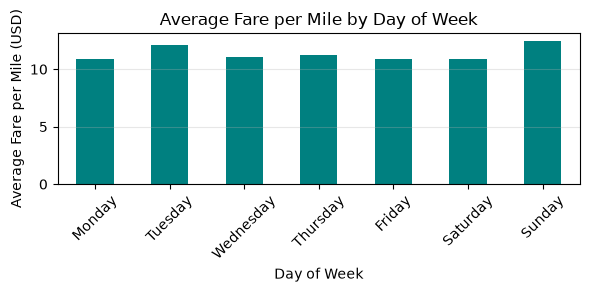

In [134]:
# Compare the average fare per mile for different days and for different times of the day

# Filter trips with positive distance
analysis_df = trip_df[(trip_df['trip_distance'] > 0)].copy()

# Add hour and day of week
analysis_df['hour'] = analysis_df['tpep_pickup_datetime'].dt.hour
analysis_df['day_of_week'] = analysis_df['tpep_pickup_datetime'].dt.day_name()

# Calculate fare per mile
analysis_df['fare_per_mile'] = analysis_df['fare_amount'] / analysis_df['trip_distance']

# By hour of day
fare_by_hour = analysis_df.groupby('hour')['fare_per_mile'].mean()

print("Average Fare per Mile by Hour of Day:")
print(fare_by_hour)

plt.figure(figsize=(7, 3))
fare_by_hour.plot(kind='bar', color='steelblue')
plt.xlabel('Hour of Day')
plt.ylabel('Average Fare per Mile (USD)')
plt.title('Average Fare per Mile by Hour of Day')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# By day of week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
fare_by_day = analysis_df.groupby('day_of_week')['fare_per_mile'].mean().reindex(day_order)

print("\nAverage Fare per Mile by Day of Week:")
print(fare_by_day)

plt.figure(figsize=(6, 3))
fare_by_day.plot(kind='bar', color='teal')
plt.xlabel('Day of Week')
plt.ylabel('Average Fare per Mile (USD)')
plt.title('Average Fare per Mile by Day of Week')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**3.2.11** <font color = red>[3 marks]</font> <br>
Analyse the average fare per mile for the different vendors for different hours of the day

Average Fare per Mile by Vendor and Hour of Day:
hour             0          1          2          3          4          5   \
VendorID                                                                     
1          6.792740   7.050094   6.924039   6.502521   7.492353   6.962445   
2         11.518571  12.393426  10.741141  12.025127  14.934076  16.531217   
6          4.363383   5.728431        NaN        NaN  55.510204   3.889734   

hour             6          7          8          9   ...         14  \
VendorID                                              ...              
1          6.648190   7.192409   8.071597   8.393330  ...   8.648833   
2         12.805174  11.373496  11.188726  11.280933  ...  12.614030   
6          3.892467   4.238542   5.220734   6.822444  ...   5.695402   

hour             15         16         17         18         19         20  \
VendorID                                                                     
1          8.814057   8.827550   8.651106  

<Figure size 1000x400 with 0 Axes>

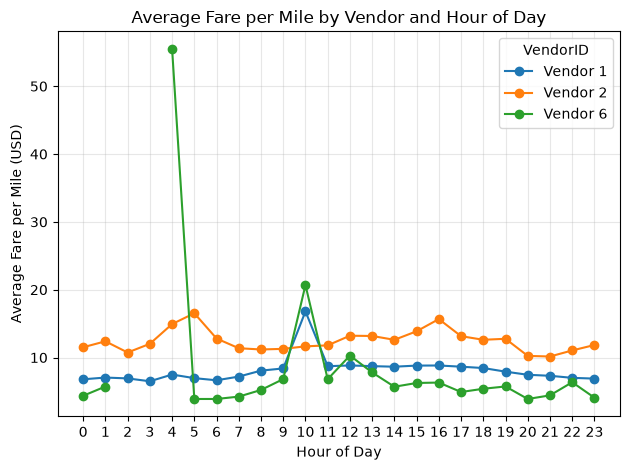

In [135]:
# Compare fare per mile for different vendors

# Filter trips with positive distance
analysis_df = trip_df[(trip_df['trip_distance'] > 0)].copy()

# Add hour and vendor
analysis_df['hour'] = analysis_df['tpep_pickup_datetime'].dt.hour
analysis_df['fare_per_mile'] = analysis_df['fare_amount'] / analysis_df['trip_distance']

# By vendor and hour
fare_by_vendor_hour = analysis_df.groupby(['VendorID', 'hour'])['fare_per_mile'].mean().unstack()

print("Average Fare per Mile by Vendor and Hour of Day:")
print(fare_by_vendor_hour)

plt.figure(figsize=(10, 4))
fare_by_vendor_hour.T.plot(kind='line', marker='o')
plt.xlabel('Hour of Day')
plt.ylabel('Average Fare per Mile (USD)')
plt.title('Average Fare per Mile by Vendor and Hour of Day')
plt.xticks(range(24))
plt.legend(title='VendorID', labels=[f'Vendor {int(v)}' for v in fare_by_vendor_hour.index])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**3.2.12** <font color = red>[5 marks]</font> <br>
Compare the fare rates of the different vendors in a tiered fashion. Analyse the average fare per mile for distances upto 2 miles. Analyse the fare per mile for distances from 2 to 5 miles. And then for distances more than 5 miles.


VendorID                   1          2          6
distance_tier                                     
up to 2 miles      10.635032  18.005383  32.422471
2 to 5 miles        6.380893   6.537991   8.107119
more than 5 miles   4.423563   4.490261   4.382026


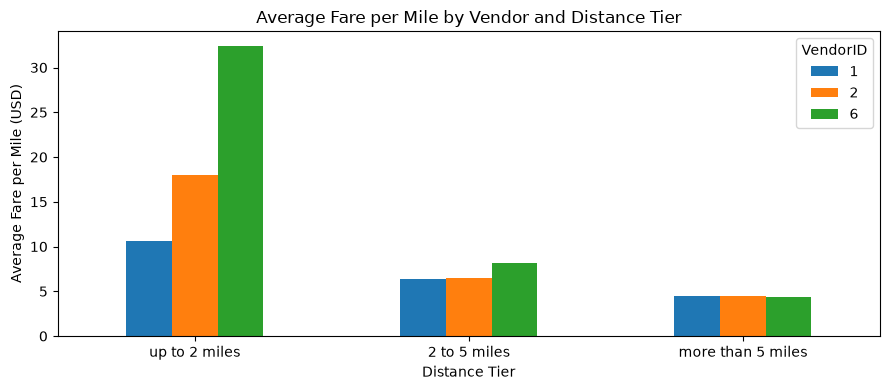

In [136]:
# Defining distance tiers
# Define distance tiers and compare average fare per mile by vendor
tiered_df = trip_df[(trip_df['trip_distance'] > 0) & (trip_df['fare_amount'] >= 0)].copy()
tiered_df['fare_per_mile'] = tiered_df['fare_amount'] / tiered_df['trip_distance']

tiered_df['distance_tier'] = pd.cut(
    tiered_df['trip_distance'],
    bins=[0, 2, 5, float('inf')],
    labels=['up to 2 miles', '2 to 5 miles', 'more than 5 miles'],
    right=True
)

fare_by_vendor_tier = (
    tiered_df
    .groupby(['distance_tier', 'VendorID'])['fare_per_mile']
    .mean()
    .unstack()
)

print(fare_by_vendor_tier)

fare_by_vendor_tier.plot(
    kind='bar',
    figsize=(9, 4),
    rot=0
)
plt.xlabel('Distance Tier')
plt.ylabel('Average Fare per Mile (USD)')
plt.title('Average Fare per Mile by Vendor and Distance Tier')
plt.legend(title='VendorID')
plt.tight_layout()
plt.show()


##### Customer Experience and Other Factors

**3.2.13** <font color = red>[5 marks]</font> <br>
Analyse average tip percentages based on trip distances, passenger counts and time of pickup. What factors lead to low tip percentages?

Average tip % by trip distance tier: distance_tier
0-1 miles     26.872089
1-2 miles     21.191221
2-5 miles     18.639749
5-10 miles    19.266736
10+ miles     15.813881
Name: tip_pct, dtype: float64

Average tip % by passenger count: passenger_count
1.0    21.592003
2.0    20.455295
3.0    18.967309
4.0    17.379818
5.0    20.522174
6.0    20.581536
Name: tip_pct, dtype: float64

Average tip % by pickup hour: pickup_hour
0     25.872895
1     20.562824
2     20.186266
3     19.958252
4     18.311512
5     17.187506
6     17.947651
7     19.255079
8     19.682646
9     19.540640
10    19.187722
11    19.082714
12    19.079022
13    19.886917
14    20.793250
15    25.070829
16    20.716957
17    24.096159
18    21.927693
19    22.016685
20    21.278898
21    21.317309
22    20.890508
23    23.528128
Name: tip_pct, dtype: float64


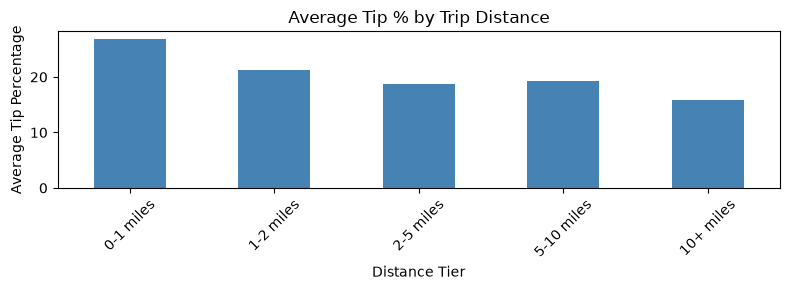

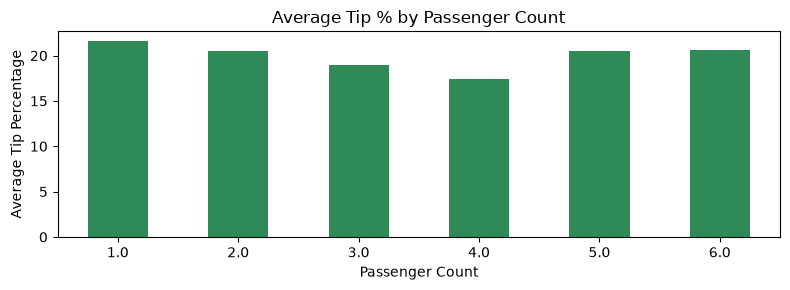

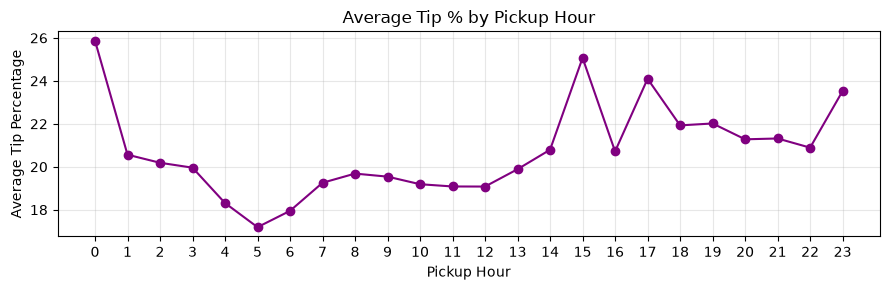


Low tip trips (< 10%): 505951 , (27.1% of total trips with tip)

Low tip share by distance tier:
distance_tier
10+ miles     32.69
0-1 miles     30.73
5-10 miles    30.26
2-5 miles     25.19
1-2 miles     23.70
dtype: float64

Low tip share by passenger count:
passenger_count
4.0    36.71
3.0    30.62
2.0    27.96
1.0    26.56
6.0    25.72
5.0    25.59
dtype: float64

Low tip share by pickup hour:
pickup_hour
4     39.33
5     38.35
3     33.65
6     32.93
2     29.98
13    29.63
12    29.31
11    29.25
15    29.14
14    29.13
dtype: float64


In [137]:
#  Analyze tip percentages based on distances, passenger counts and pickup times
# Analyse tip percentage
tip_df = trip_df[
    (trip_df['fare_amount'] > 0) &
    (trip_df['passenger_count'] > 0) &
    (trip_df['tip_amount'] >= 0) &
    (trip_df['trip_distance'] >= 0)
].copy()

tip_df['tip_pct'] = tip_df['tip_amount'] / tip_df['fare_amount'] * 100
tip_df['pickup_hour'] = tip_df['tpep_pickup_datetime'].dt.hour
tip_df['distance_tier'] = pd.cut(
    tip_df['trip_distance'],
    bins=[-0.01, 1, 2, 5, 10, tip_df['trip_distance'].max()],
    labels=['0-1 miles', '1-2 miles', '2-5 miles', '5-10 miles', '10+ miles']
)

distance_tip = tip_df.groupby('distance_tier')['tip_pct'].mean()
passenger_tip = tip_df.groupby('passenger_count')['tip_pct'].mean()
hour_tip = tip_df.groupby('pickup_hour')['tip_pct'].mean()

print("Average tip % by trip distance tier:", distance_tip)
print("\nAverage tip % by passenger count:",passenger_tip)
print("\nAverage tip % by pickup hour:",hour_tip)

plt.figure(figsize=(8, 3))
distance_tip.plot(kind='bar', color='steelblue')
plt.xlabel('Distance Tier')
plt.ylabel('Average Tip Percentage')
plt.title('Average Tip % by Trip Distance')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
passenger_tip.plot(kind='bar', color='seagreen')
plt.xlabel('Passenger Count')
plt.ylabel('Average Tip Percentage')
plt.title('Average Tip % by Passenger Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 3))
hour_tip.plot(kind='line', marker='o', color='purple')
plt.xlabel('Pickup Hour')
plt.ylabel('Average Tip Percentage')
plt.title('Average Tip % by Pickup Hour')
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

low_tip = tip_df[tip_df['tip_pct'] < 10]
low_tip_rate = len(low_tip) / len(tip_df) * 100

print(f"\nLow tip trips (< 10%): {len(low_tip)} , ({low_tip_rate:.1f}% of total trips with tip)")

low_by_distance = low_tip.groupby('distance_tier').size()
total_by_distance = tip_df.groupby('distance_tier').size()
print("\nLow tip share by distance tier:")
print((low_by_distance / total_by_distance * 100).sort_values(ascending=False).round(2))

low_by_passenger = low_tip.groupby('passenger_count').size()
total_by_passenger = tip_df.groupby('passenger_count').size()
print("\nLow tip share by passenger count:")
print((low_by_passenger / total_by_passenger * 100).sort_values(ascending=False).round(2))

low_by_hour = low_tip.groupby('pickup_hour').size()
total_by_hour = tip_df.groupby('pickup_hour').size()
print("\nLow tip share by pickup hour:")
print((low_by_hour / total_by_hour * 100).sort_values(ascending=False).head(10).round(2))


Additional analysis [optional]: Let's try comparing cases of low tips with cases of high tips to find out if we find a clear aspect that drives up the tipping behaviours

Low-tip trips (<10%): 505951
High-tip trips (>25%): 815534

Summary comparison:
                    Low tip (<10%) High tip (>25%)
count                       505951          815534
avg_fare_amount              22.09           14.48
avg_trip_distance             3.73            2.31
avg_passenger_count           1.41            1.36
mode_pickup_hour                15              18
mode_payment_type                2               1
mode_vendor                      2               2
mode_distance_tier       1-2 miles       1-2 miles

Distance tier share:
               Low tip (<10%)  High tip (>25%)
distance_tier                                 
0-1 miles            0.268593         0.297703
1-2 miles            0.279640         0.401445
2-5 miles            0.251297         0.213659
5-10 miles           0.096256         0.049227
10+ miles            0.104214         0.037967


<Figure size 800x300 with 0 Axes>

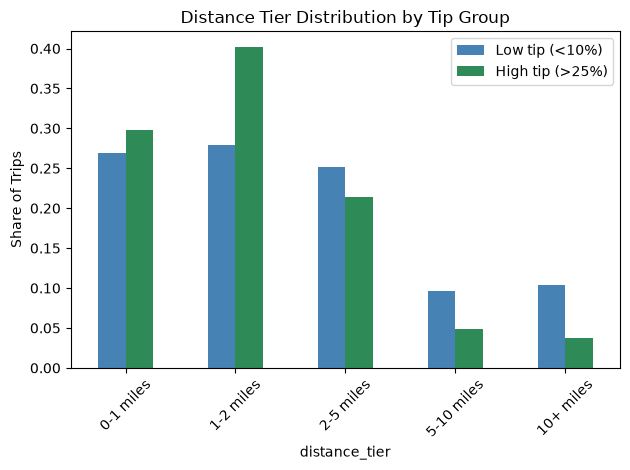

In [138]:
# Compare trips with tip percentage < 10% to trips with tip percentage > 25%
low_tip = tip_df[tip_df['tip_pct'] < 10].copy()
high_tip = tip_df[tip_df['tip_pct'] > 25].copy()

print(f"Low-tip trips (<10%): {len(low_tip)}")
print(f"High-tip trips (>25%): {len(high_tip)}")

summary = pd.DataFrame(
    {
        'Low tip (<10%)': [
            len(low_tip),
            round(low_tip['fare_amount'].mean(), 2),
            round(low_tip['trip_distance'].mean(), 2),
            round(low_tip['passenger_count'].mean(), 2),
            low_tip['pickup_hour'].mode().iloc[0],
            low_tip['payment_type'].mode().iloc[0],
            low_tip['VendorID'].mode().iloc[0],
            low_tip['distance_tier'].mode().iloc[0],
        ],
        'High tip (>25%)': [
            len(high_tip),
            round(high_tip['fare_amount'].mean(), 2),
            round(high_tip['trip_distance'].mean(), 2),
            round(high_tip['passenger_count'].mean(), 2),
            high_tip['pickup_hour'].mode().iloc[0],
            high_tip['payment_type'].mode().iloc[0],
            high_tip['VendorID'].mode().iloc[0],
            high_tip['distance_tier'].mode().iloc[0],
        ]
    },
    index=[
        'count',
        'avg_fare_amount',
        'avg_trip_distance',
        'avg_passenger_count',
        'mode_pickup_hour',
        'mode_payment_type',
        'mode_vendor',
        'mode_distance_tier'
    ]
)

print("\nSummary comparison:")
print(summary)

distance_comp = pd.DataFrame(
    {
        'Low tip (<10%)': low_tip['distance_tier'].value_counts(normalize=True).reindex(
            ['0-1 miles', '1-2 miles', '2-5 miles', '5-10 miles', '10+ miles'],
            fill_value=0
        ),
        'High tip (>25%)': high_tip['distance_tier'].value_counts(normalize=True).reindex(
            ['0-1 miles', '1-2 miles', '2-5 miles', '5-10 miles', '10+ miles'],
            fill_value=0
        )
    }
)

print("\nDistance tier share:")
print(distance_comp)

plt.figure(figsize=(8, 3))
distance_comp.plot(kind='bar', color=['steelblue', 'seagreen'])
plt.title('Distance Tier Distribution by Tip Group')
plt.ylabel('Share of Trips')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**3.2.14** <font color = red>[3 marks]</font> <br>
Analyse the variation of passenger count across hours and days of the week.

Average passenger count by pickup hour:
pickup_hour
0     1.397671
1     1.400511
2     1.413203
3     1.415667
4     1.348533
5     1.255029
6     1.221184
7     1.244420
8     1.260969
9     1.288115
10    1.326945
11    1.338080
12    1.354847
13    1.357221
14    1.364370
15    1.380551
16    1.378385
17    1.363527
18    1.350242
19    1.364786
20    1.373821
21    1.401134
22    1.403022
23    1.393123
Name: passenger_count, dtype: float64

Average passenger count by day of week:
pickup_day
Monday       1.334204
Tuesday      1.307604
Wednesday    1.303972
Thursday     1.316229
Friday       1.369408
Saturday     1.446065
Sunday       1.429836
Name: passenger_count, dtype: float64


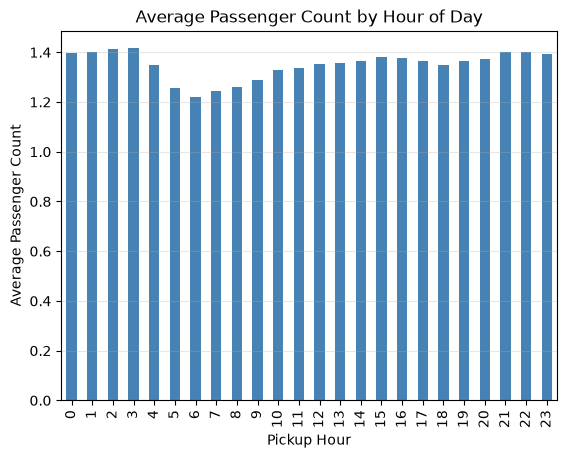

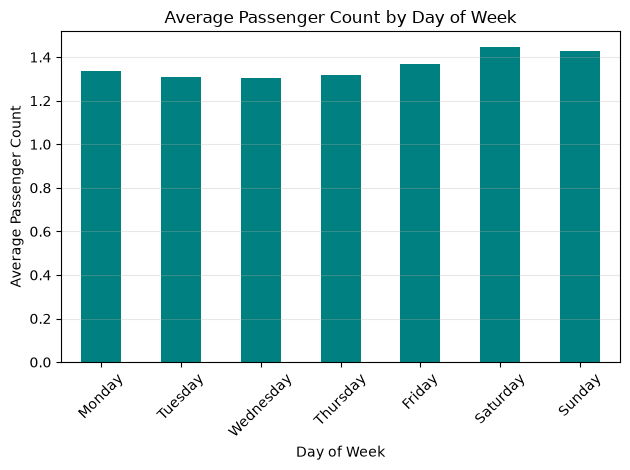

In [139]:
# See how passenger count varies across hours and days

trip_df['pickup_hour'] = trip_df['tpep_pickup_datetime'].dt.hour
trip_df['pickup_day'] = trip_df['tpep_pickup_datetime'].dt.day_name()

hourly_avg_passengers = trip_df.groupby('pickup_hour')['passenger_count'].mean()
daily_avg_passengers = trip_df.groupby('pickup_day')['passenger_count'].mean().reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])


print("Average passenger count by pickup hour:")
print(hourly_avg_passengers)

print("\nAverage passenger count by day of week:")
print(daily_avg_passengers)


hourly_avg_passengers.plot(kind='bar', color='steelblue')
plt.xlabel('Pickup Hour')
plt.ylabel('Average Passenger Count')
plt.title('Average Passenger Count by Hour of Day')
plt.grid(axis='y', alpha=0.3)
plt.show()

daily_avg_passengers.plot(kind='bar', color='teal')
plt.xlabel('Day of Week')
plt.ylabel('Average Passenger Count')
plt.title('Average Passenger Count by Day of Week')
plt.grid(axis='y', alpha=0.3)
plt.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


**3.2.15** <font color = red>[2 marks]</font> <br>
Analyse the variation of passenger counts across zones

Top 10 zones by average passenger count:
                                      avg_passengers
PULocationID PUZone                                 
6            Arrochar/Fort Wadsworth        1.840000
204          Rossville/Woodrow              1.800000
12           Battery Park                   1.708680
195          Red Hook                       1.682609
1            Newark Airport                 1.568807
178          Ocean Parkway South            1.533333
261          World Trade Center             1.512178
59           Crotona Park                   1.500000
58           Country Club                   1.500000
199          Rikers Island                  1.500000


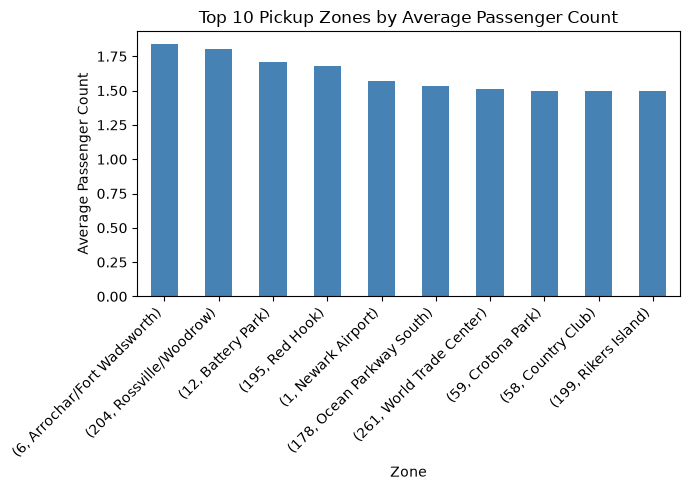

In [140]:
# How does passenger count vary across zones
zone_passenger_stats = (
    trip_df
    .groupby(['PULocationID', 'PUZone'])['passenger_count']
    .agg(
        avg_passengers='mean'
    )
    .sort_values('avg_passengers', ascending=False)
)

print("Top 10 zones by average passenger count:")
print(zone_passenger_stats.head(10))

plt.figure(figsize=(7, 5))
zone_passenger_stats.head(10)['avg_passengers'].plot(kind='bar', color='steelblue')
plt.xlabel('Zone')
plt.ylabel('Average Passenger Count')
plt.title('Top 10 Pickup Zones by Average Passenger Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [141]:
# For a more detailed analysis, we can use the zones_with_trips GeoDataFrame
# Create a new column for the average passenger count in each zone.

# compute average passenger count per pickup location and merge into zones GeoDataFrame
avg_passengers = trip_df.groupby('PULocationID')['passenger_count'].mean().rename('avg_passenger_count')
zones_with_trips = zones.merge(avg_passengers, left_on='LocationID', right_index=True, how='left')
zones_with_trips['avg_passenger_count'] = zones_with_trips['avg_passenger_count'].fillna(0)
zones_with_trips.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry,trip_count,avg_passenger_count
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19...",218.0,1.568807
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343...",2.0,1.000000
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2...",44.0,1.022727
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20...",2355.0,1.323567
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144...",13.0,1.000000


Find out how often surcharges/extra charges are applied to understand their prevalance

In [142]:
surcharge_cols = [
    'extra',
    'mta_tax',
    'tolls_amount',
    'improvement_surcharge',
    'congestion_surcharge',
    'airport_fee'
]

surcharge_stats = []
for col in surcharge_cols:
    non_zero = (trip_df[col] > 0).sum()
    pct_non_zero = non_zero / len(trip_df) * 100
    total_amount = trip_df[col].sum()
    surcharge_stats.append({
        'charge': col,
        'trips_with_charge': non_zero,
        'pct_trips_with_charge': pct_non_zero,
        'total_amount': total_amount
    })

surcharge_df = pd.DataFrame(surcharge_stats).set_index('charge')
print(surcharge_df)

any_surcharge_mask = (trip_df[surcharge_cols] > 0).any(axis=1)
print("\nTrips with any surcharge/extra charge:",any_surcharge_mask.sum())
print("\nTrips % with any surcharge", f'({any_surcharge_mask.mean() *100})')

                       trips_with_charge  pct_trips_with_charge  total_amount
charge                                                                       
extra                            1139587              60.093104  3.011519e+06
mta_tax                          1878661              99.066215  9.393502e+05
tolls_amount                      153832               8.111923  1.131465e+06
improvement_surcharge            1895521              99.955283  1.894624e+06
congestion_surcharge             1755486              92.570908  4.376240e+06
airport_fee                       225811              11.907545  2.710245e+05

Trips with any surcharge/extra charge: 1895848

Trips % with any surcharge (99.97252644395684)


**3.2.16** <font color = red>[5 marks]</font> <br>
Analyse the pickup/dropoff zones or times when extra charges are applied more frequently

In [143]:
# How often is each surcharge applied?
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

drop_zone_map = zones[['LocationID', 'zone']].rename(
    columns={'LocationID': 'DOLocationID', 'zone': 'DOZone'}
)
trip_with_do = trip_df.merge(drop_zone_map, on='DOLocationID', how='left')

for col in surcharge_cols:
    mask = trip_df[col] > 0
    total = mask.sum()
    pct = total / len(trip_df) * 100

    pickup_zone_freq = trip_df.loc[mask, 'PUZone'].value_counts().head(1)
    drop_zone_freq = drop_zone_map.loc[mask, 'DOZone'].value_counts().head(1)

    pickup_hour_freq = trip_df.loc[mask, 'tpep_pickup_datetime'].dt.hour.value_counts().nlargest(1)
    dropoff_hour_freq = trip_df.loc[mask, 'tpep_dropoff_datetime'].dt.hour.value_counts().nlargest(1)

    print(f"Extra charge type - {col}: {total} trips ({pct:.2f}% of all trips)")
    print("Top pickup zones:")
    print(pickup_zone_freq)
    print("Top dropoff zones:")
    print(drop_zone_freq)
    print("Top pickup hours:")
    print(pickup_hour_freq)
    print("Top dropoff hours:")
    print(dropoff_hour_freq)


Extra charge type - extra: 1139587 trips (60.09% of all trips)
Top pickup zones:
PUZone
LaGuardia Airport    63576
Name: count, dtype: int64
Top dropoff zones:
DOZone
Corona    2
Name: count, dtype: int64
Top pickup hours:
tpep_pickup_datetime
18    104817
Name: count, dtype: int64
Top dropoff hours:
tpep_dropoff_datetime
18    108416
Name: count, dtype: int64
Extra charge type - mta_tax: 1878661 trips (99.07% of all trips)
Top pickup zones:
PUZone
JFK Airport    94964
Name: count, dtype: int64
Top dropoff zones:
DOZone
Governor's Island/Ellis Island/Liberty Island    3
Name: count, dtype: int64
Top pickup hours:
tpep_pickup_datetime
18    132936
Name: count, dtype: int64
Top dropoff hours:
tpep_dropoff_datetime
18    137091
Name: count, dtype: int64
Extra charge type - tolls_amount: 153832 trips (8.11% of all trips)
Top pickup zones:
PUZone
JFK Airport    47061
Name: count, dtype: int64
Top dropoff zones:
DOZone
Bayside    1
Name: count, dtype: int64
Top pickup hours:
tpep_pickup_date

## **4** Conclusion
<font color = red>[15 marks]</font> <br>

### **4.1** Final Insights and Recommendations
<font color = red>[15 marks]</font> <br>

Conclude your analyses here. Include all the outcomes you found based on the analysis.

Based on the insights, frame a concluding story explaining suitable parameters such as location, time of the day, day of the week etc. to be kept in mind while devising a strategy to meet customer demand and optimise supply.

**4.1.1** <font color = red>[5 marks]</font> <br>
Recommendations to optimize routing and dispatching based on demand patterns and operational inefficiencies

- Peak hours
    - Deploy more vehicles during peak demand windows (especially 4PM-7PM and 10AM-3PM) and reduce fleet size during quiet night hours (11PM-5AM).
- Driver availability
    - Maintain higher driver availability Mon-Fri 7AM-9PM. Over weekend flexible scheduling and maintenance windows as demand is low.
- Vehicle deploymnet
    - Position supply near top pickup zones like JFK Airport, LaGuardia, Midtown, Upper East Side, Penn Station, and night hotspots such as East Village and Murray Hill.
- High pickup/low dropoff Ratios indicate supply concentration opportunities - East Elmhurst , JFK Airport, LaGuardia Airport. Implement surge pricing during peak hours
- Night dispatching
    - Prioritize night dispatching in high drop off zone - East Village, Clinton East, Murray Hill (top 3 dropoff zones). Deploy ride-pooling options to reduce vehicle count while maintaining service
- Rerouting
    - Monitor slow routes by hour and reroute congested trips to improve turnaround and reduce idle time.Suggest alternative routes during 4PM-7PM and redirect drivers via less congested corridors
- Car types
    - Use smaller cars for short-distance trips(0-2 miles - 51% of total trips) and reserve larger or premium vehicles for airport and longer-distance routes.
- Surge pricing
    - To optimize revenue implement surge pricing. +20-25% (4PM-7PM), +10-15%(7AM-10AM, 10PM-11PM), other times standard rates, Discount at night hours.
- Promotional prising 
    - During quarters Q1 and Q3 to increase demand
- Balance supply using pickup/dropoff ratio insights to prevent oversupply in some zones and shortages in others.
- Standardize pricing across vendors or justify premium for superior service metrics
- Extra Charges: Only 60.09% of trips - underutilized revenue opportunity. Increase extra charge frequency during peak hours (4PM-7PM) for rush period premium
- Cash payments (payment type 2) associated with 67% of low-tip trips, Incentivize card payments (5% lower fare or bonus points) to improve tip capture

**4.1.2** <font color = red>[5 marks]</font> <br>

Suggestions on strategically positioning cabs across different zones to make best use of insights uncovered by analysing trip trends across time, days and months.

- Peak-hour staging
    - Pre-position drivers 20–30 minutes before peak (16:00–19:00) in top pickup zones (Midtown Center, Midtown East, Upper East Side South, Penn Station, Times Sq) to shorten wait times and increase throughput.

- Airport handling
    - Maintain dedicated airport fleets at JFK and LaGuardia with separate queueing; rotate drivers to/from nearby high pickup zones to avoid deadhead miles.

- Use pickup/dropoff ratio to rebalance
    - Move idle vehicles from high-drop / low-pick zones to high-pick / low-drop zones (e.g., shift capacity toward East Elmhurst, JFK, LaGuardia during peak departures).

- Night coverage (23:00–05:00)
    - Concentrate night drivers in high night-time pickup/dropoff zones (East Village, Clinton East, Murray Hill, East Chelsea, TriBeCa) and keep a small roaming fleet for airport late arrivals.

- Micro-hubs and staging clusters
    - Create micro-hubs near clusters of high-demand zones (e.g., Midtown cluster, Upper East/West) for quick redeployment and driver rest/vehicle swap.

- Fleet mix by zone & distance tiers
    - Assign small, fuel-efficient cars to short-trip dense zones (0–2 miles); sedans for 2–5 mile corridors; larger/premium vehicles for airport and long-haul trips (>5 miles).

- Dynamic repositioning & demand prediction
    - Use short-term demand forecasts (1–2 hours) to reallocate drivers; trigger automatic repositioning when predicted supply-demand imbalance exceeds threshold.

- Incentives & driver routing
    - Offer relocation bonuses to drivers who reposition to undersupplied high-pickup zones before peaks; reward drivers taking pooled/shared rides during off-peak to improve utilization.

- Time & day-specific policies
    - Increase supply in March–June and Oct–Dec during historically higher demand; schedule maintenance and training in Jan–Feb and Jul–Sep lower-demand windows.

- Congestion-aware routing
    - Route drivers around identified slow corridors during peak hours; prioritize routes with better throughput for airport-bound trips to reduce delay penalties.

**4.1.3** <font color = red>[5 marks]</font> <br>
Propose data-driven adjustments to the pricing strategy to maximize revenue while maintaining competitive rates with other vendors.

- Use distance-tier pricing: 
    - Short trips (up to 2 miles) account for the largest share of rides, so keep a slightly higher per-mile floor for that tier to cover fixed pickup costs, while offering more competitive per-mile pricing for 2–5 mile and >5 mile trips.
- Apply surge only at true peaks: 
    - Data shows highest demand around 2PM–7PM and strong weekday morning/evening peaks, so set +20–25% for late afternoon rush and +10–15% for 7–10 AM / 7–9 PM, while keeping midday and off-peak rates stable.
- Preserve market share at night: 
    - Night revenue is lower than daytime, so avoid aggressive night surges; instead offer modest incentives or loyalty discounts for 23:00–05:00 to improve utilization in top night zones such as East Village, Clinton East, and Murray Hill.
- Vendor pricing parity: 
    - Average fare-per-mile varies by vendor and distance tier, so standardize base fare structure across VendorID 1,2,6 and reserve premium pricing only for verified service advantages or faster fulfillment.
- Leverage surcharge visibility: 
    - Congestion and airport fees are already common, so ensure these are transparently bundled and not hidden; consider dynamic airport/additional charge policies only for actual airport or congestion-heavy trips to avoid customer pushback.
- Encourage digital payments: 
    - Low-tip trips are more frequent with cash payments, so offer small fare credits or rewards for card/digital transactions to improve overall revenue capture and reduce tip leakage.
- Use quarter and zone insights: 
    - Since revenue is stronger in Q2/Q4 and top pickup zones are JFK, LaGuardia, Midtown, and Upper East Side, align price adjustments with seasonality and maintain competitive rates in high-density zones to retain volume.